# Notebook 03 — Single-Frame vs Temporal Modeling

**Project:** Temporal Vision / HMDB51 subset  
**Goal:** Test whether ordered frame representations improve action classification compared with a single-frame visual representation.

This notebook reuses the saved CLIP and SigLIP embeddings. It does **not** decode videos, extract frames, download models, or regenerate embeddings.

## Experimental design

For each encoder independently (CLIP: 512 dimensions; SigLIP: 768 dimensions), train and evaluate:

1. **Single-frame baseline:** one deterministic middle frame per video → MLP classifier.
2. **Mean-pooling control:** average all frame embeddings per video → MLP classifier. This uses multiple frames but discards their order.
3. **GRU:** sequence model over ordered frame embeddings.
4. **LSTM:** sequence model over ordered frame embeddings.
5. **Transformer Encoder:** positional embeddings + self-attention over frame embeddings.
6. **Temporal CNN:** temporal convolutions over the frame sequence.

After training, evaluate each temporal model again with the test sequence order shuffled. This is an order-sensitivity diagnostic, not a separately trained model.

**Fairness and leakage prevention**
- Split by video, never by frame. Frames from one video cannot appear in multiple splits.
- Use the same train/validation/test video IDs for every architecture and both encoders.
- Fit label mappings from the training data only; preserve one shared class mapping.
- Select checkpoints using validation macro-F1.
- Use the test set only for final evaluation.
- Keep architecture sizes modest and use early stopping.

**Interpretation caution:** This is a small-subset experiment with frozen pretrained visual embeddings. Results support conclusions about this dataset subset and setup, not universal claims about video understanding.

## 0. Environment and reproducibility

Run this notebook from the project root (`Tracking`). If required packages are missing, install them in the active project environment before continuing.

In [1]:
# If needed, uncomment and run in your project venv:
# %pip install numpy pandas matplotlib scikit-learn torch tqdm

import os
import json
import time
import math
import random
import platform
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, "mps"):
        # Deterministic MPS support varies by operation/version.
        pass

set_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("NumPy:", np.__version__)

Python: 3.11.15
PyTorch: 2.15.0
Device: mps
NumPy: 2.4.6


## 1. Project paths and output layout

Expected project root:

`/Users/vanshikaarora/Desktop/Tracking`

The output folder will be created at the project root as `Single-multiframe/`.

In [2]:
PROJECT_ROOT = Path("/Users/vanshikaarora/Desktop/Tracking")

# If the notebook is moved to another machine, use the current working directory
# only when it clearly contains the existing embeddings folder.
if not PROJECT_ROOT.exists():
    candidate = Path.cwd()
    if (candidate / "embeddings").exists():
        PROJECT_ROOT = candidate
    else:
        raise FileNotFoundError(
            f"Project root not found: {PROJECT_ROOT}. "
            "Update PROJECT_ROOT to the folder containing embeddings/."
        )

EMBEDDINGS_ROOT = PROJECT_ROOT / "embeddings"
OUTPUT_ROOT = PROJECT_ROOT / "Single-multiframe"

ENCODER_CONFIG = {
    "clip": {
        "embedding_dir": EMBEDDINGS_ROOT / "embedding-store" / "clip",
        "expected_dim": 512,
    },
    "siglip": {
        "embedding_dir": EMBEDDINGS_ROOT / "embedding-store" / "siglip",
        "expected_dim": 768,
    },
}

# Folder names intentionally separate the single-frame baseline from
# sequence-based temporal architectures.
BASELINE_ROOT = OUTPUT_ROOT / "Baseline"
TEMPORAL_ROOT = OUTPUT_ROOT / "Temporal"
EVALUATION_ROOT = OUTPUT_ROOT / "Evaluation"
SPLIT_ROOT = OUTPUT_ROOT / "data-splits"

for path in [BASELINE_ROOT, TEMPORAL_ROOT, EVALUATION_ROOT, SPLIT_ROOT]:
    path.mkdir(parents=True, exist_ok=True)

for encoder in ENCODER_CONFIG:
    (BASELINE_ROOT / encoder).mkdir(parents=True, exist_ok=True)
    (TEMPORAL_ROOT / "GRU" / encoder).mkdir(parents=True, exist_ok=True)
    (TEMPORAL_ROOT / "LSTM" / encoder).mkdir(parents=True, exist_ok=True)
    (TEMPORAL_ROOT / "Transformer_Encoder" / encoder).mkdir(parents=True, exist_ok=True)
    (TEMPORAL_ROOT / "Temporal_CNN" / encoder).mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Embeddings root:", EMBEDDINGS_ROOT)
print("Experiment outputs:", OUTPUT_ROOT)

Project root: /Users/vanshikaarora/Desktop/Tracking
Embeddings root: /Users/vanshikaarora/Desktop/Tracking/embeddings
Experiment outputs: /Users/vanshikaarora/Desktop/Tracking/Single-multiframe


## 2. Load and validate the saved embedding stores

Each encoder store must contain:
- `frame_embeddings.npy`
- `frame_manifest.csv`
- `embedding_metadata.json`

The manifest is the source of frame-to-video and frame-to-label relationships. The notebook detects common column-name variants and prints the resolved schema. If your manifest uses an unusual column name, set the override in the configuration cell below.

In [3]:
# Optional explicit column overrides. Leave as None for automatic detection.
COLUMN_OVERRIDES = {
    "video_id": None,       # e.g. "video_id"
    "label": None,          # e.g. "label"
    "frame_index": None,    # e.g. "frame_index"
}

COLUMN_CANDIDATES = {
    "video_id": ["video_id", "video", "sequence_id", "video_name", "filename", "video_path"],
    "label": ["label", "class", "class_name", "action", "category"],
    "frame_index": ["frame_index", "frame_idx", "frame_number", "frame_id", "index"],
}

def resolve_column(df, logical_name):
    override = COLUMN_OVERRIDES.get(logical_name)
    if override is not None:
        if override not in df.columns:
            raise KeyError(f"Configured {logical_name} column '{override}' not found.")
        return override
    for candidate in COLUMN_CANDIDATES[logical_name]:
        if candidate in df.columns:
            return candidate
    raise KeyError(
        f"Could not resolve {logical_name}. Available columns: {list(df.columns)}. "
        f"Set COLUMN_OVERRIDES['{logical_name}'] explicitly."
    )

def load_encoder_store(encoder_name, config):
    store = config["embedding_dir"]
    emb_path = store / "frame_embeddings.npy"
    manifest_path = store / "frame_manifest.csv"
    metadata_path = store / "embedding_metadata.json"

    for p in [emb_path, manifest_path, metadata_path]:
        if not p.exists():
            raise FileNotFoundError(f"Required saved embedding artifact missing: {p}")

    embeddings = np.load(emb_path, mmap_mode="r")
    manifest = pd.read_csv(manifest_path)

    if embeddings.ndim != 2:
        raise ValueError(f"{encoder_name}: expected 2D embeddings, got {embeddings.shape}")
    if len(manifest) != embeddings.shape[0]:
        raise ValueError(
            f"{encoder_name}: manifest rows ({len(manifest)}) do not match "
            f"embedding rows ({embeddings.shape[0]})."
        )

    video_col = resolve_column(manifest, "video_id")
    label_col = resolve_column(manifest, "label")
    frame_col = resolve_column(manifest, "frame_index")

    manifest = manifest.copy()
    manifest["_video_id"] = manifest[video_col].astype(str)
    manifest["_label"] = manifest[label_col].astype(str)
    manifest["_frame_index"] = pd.to_numeric(manifest[frame_col], errors="coerce")

    if manifest["_frame_index"].isna().any():
        raise ValueError(f"{encoder_name}: frame index contains missing/non-numeric values.")
    if manifest["_video_id"].isna().any() or manifest["_label"].isna().any():
        raise ValueError(f"{encoder_name}: video IDs or labels contain missing values.")

    # Embedding row position is the authoritative row-to-vector mapping.
    manifest["_embedding_row"] = np.arange(len(manifest), dtype=np.int64)

    metadata = json.loads(metadata_path.read_text())
    print(f"\n{encoder_name.upper()}")
    print("  embeddings:", embeddings.shape, embeddings.dtype)
    print("  manifest columns:", list(manifest.columns))
    print("  resolved source columns:", {
        "video_id": video_col, "label": label_col, "frame_index": frame_col
    })
    print("  videos:", manifest["_video_id"].nunique())
    print("  classes:", manifest["_label"].nunique())
    print("  metadata keys:", list(metadata.keys())[:20])

    if embeddings.shape[1] != config["expected_dim"]:
        raise ValueError(
            f"{encoder_name}: expected dimension {config['expected_dim']}, "
            f"found {embeddings.shape[1]}."
        )

    return embeddings, manifest, metadata

ENCODER_DATA = {}
for name, cfg in ENCODER_CONFIG.items():
    ENCODER_DATA[name] = load_encoder_store(name, cfg)


CLIP
  embeddings: (6662, 512) float32
  manifest columns: ['embedding_row', 'video_id', 'label', 'frame_index', 'frame_position', 'timestamp_sec', 'frame_path', '_video_id', '_label', '_frame_index', '_embedding_row']
  resolved source columns: {'video_id': 'video_id', 'label': 'label', 'frame_index': 'frame_index'}
  videos: 950
  classes: 9
  metadata keys: ['model_id', 'model_kind', 'num_frames', 'embedding_dimension', 'l2_normalized', 'device', 'batch_size', 'source_manifest']

SIGLIP
  embeddings: (6662, 768) float32
  manifest columns: ['embedding_row', 'video_id', 'label', 'frame_index', 'frame_position', 'timestamp_sec', 'frame_path', '_video_id', '_label', '_frame_index', '_embedding_row']
  resolved source columns: {'video_id': 'video_id', 'label': 'label', 'frame_index': 'frame_index'}
  videos: 950
  classes: 9
  metadata keys: ['model_id', 'model_kind', 'num_frames', 'embedding_dimension', 'l2_normalized', 'device', 'batch_size', 'source_manifest']


## 3. Build video-level sequences and validate ordering

We group frame embeddings by video ID, sort by the recorded frame index, and verify:
- one class label per video;
- no duplicate frame indices within a video;
- at least two frames per video;
- matching video IDs and labels across CLIP and SigLIP;
- finite embedding values.

The sequence remains variable length; padding is added only within a batch, with lengths retained so models can ignore padded positions.

In [4]:
def build_video_records(embeddings, manifest, encoder_name):
    records = []
    for video_id, group in manifest.groupby("_video_id", sort=True):
        group = group.sort_values("_frame_index", kind="stable")
        labels = group["_label"].unique()
        if len(labels) != 1:
            raise ValueError(f"{encoder_name}: video {video_id} has labels {labels}")
        frame_indices = group["_frame_index"].to_numpy()
        if len(np.unique(frame_indices)) != len(frame_indices):
            raise ValueError(f"{encoder_name}: duplicate frame indices in {video_id}")
        rows = group["_embedding_row"].to_numpy(dtype=np.int64)
        sequence = np.asarray(embeddings[rows], dtype=np.float32)
        if len(sequence) < 2:
            continue
        if not np.isfinite(sequence).all():
            raise ValueError(f"{encoder_name}: non-finite embedding in {video_id}")
        records.append({
            "video_id": str(video_id),
            "label": str(labels[0]),
            "frame_indices": frame_indices.astype(int),
            "sequence": sequence,
        })
    return records

VIDEO_RECORDS = {
    name: build_video_records(emb, manifest, name)
    for name, (emb, manifest, _) in ENCODER_DATA.items()
}

def record_signature(records):
    return {
        r["video_id"]: (r["label"], tuple(r["frame_indices"].tolist()))
        for r in records
    }

clip_signature = record_signature(VIDEO_RECORDS["clip"])
siglip_signature = record_signature(VIDEO_RECORDS["siglip"])
if clip_signature != siglip_signature:
    raise ValueError(
        "CLIP and SigLIP video/frame manifests do not match exactly. "
        "Inspect their frame_manifest.csv files before training."
    )

summary_rows = []
for encoder, records in VIDEO_RECORDS.items():
    lengths = [len(r["sequence"]) for r in records]
    summary_rows.append({
        "encoder": encoder,
        "videos": len(records),
        "classes": len(set(r["label"] for r in records)),
        "frames_total": sum(lengths),
        "frames_min": min(lengths),
        "frames_median": float(np.median(lengths)),
        "frames_max": max(lengths),
        "embedding_dim": records[0]["sequence"].shape[1],
    })

sequence_summary = pd.DataFrame(summary_rows)
display(sequence_summary)
sequence_summary.to_csv(EVALUATION_ROOT / "sequence_input_summary.csv", index=False)

# Confirm that labels are consistent across both encoder stores.
LABELS = sorted({r["label"] for r in VIDEO_RECORDS["clip"]})
LABEL_TO_ID = {label: idx for idx, label in enumerate(LABELS)}
ID_TO_LABEL = {idx: label for label, idx in LABEL_TO_ID.items()}
NUM_CLASSES = len(LABELS)

print("Class mapping:", LABEL_TO_ID)

,encoder,videos,classes,frames_total,frames_min,frames_median,frames_max,embedding_dim
0,clip,950,9,6662,7,7.0,8,512
1,siglip,950,9,6662,7,7.0,8,768


Class mapping: {'brush_hair': 0, 'cartwheel': 1, 'catch': 2, 'chew': 3, 'clap': 4, 'climb': 5, 'climb_stairs': 6, 'dive': 7, 'draw_sword': 8}


## 4. Create one shared, stratified video-level split

We create a 70% train / 15% validation / 15% test split using video IDs. This exact split is reused for both encoders and every model. The split CSVs are saved so that all experiments are auditable and reproducible.

If any class has fewer than three videos, stratification cannot reliably allocate that class to all three splits; the notebook stops rather than silently creating an invalid comparison.

In [5]:
all_records = VIDEO_RECORDS["clip"]
video_table = pd.DataFrame([
    {"video_id": r["video_id"], "label": r["label"]}
    for r in all_records
]).drop_duplicates("video_id")

class_counts = video_table["label"].value_counts()
print("Videos per class:")
display(class_counts.rename("video_count").to_frame())

if (class_counts < 3).any():
    raise ValueError(
        "At least one class has fewer than 3 videos. A stratified 70/15/15 split "
        "is not reliable. Review class counts and choose a documented alternative."
    )

train_val_ids, test_ids = train_test_split(
    video_table["video_id"].to_numpy(),
    test_size=0.15,
    random_state=SEED,
    stratify=video_table["label"].to_numpy(),
)

train_val_table = video_table.set_index("video_id").loc[train_val_ids].reset_index()
train_ids, val_ids = train_test_split(
    train_val_table["video_id"].to_numpy(),
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=train_val_table["label"].to_numpy(),
)

SPLITS = {
    "train": set(map(str, train_ids)),
    "validation": set(map(str, val_ids)),
    "test": set(map(str, test_ids)),
}

assert not (SPLITS["train"] & SPLITS["validation"])
assert not (SPLITS["train"] & SPLITS["test"])
assert not (SPLITS["validation"] & SPLITS["test"])
assert set.union(*SPLITS.values()) == set(video_table["video_id"].astype(str))

split_rows = []
for split_name, ids in SPLITS.items():
    part = video_table[video_table["video_id"].astype(str).isin(ids)].copy()
    part["split"] = split_name
    split_rows.append(part)
split_df = pd.concat(split_rows, ignore_index=True)
split_df.to_csv(SPLIT_ROOT / "video_level_splits.csv", index=False)

split_summary = (
    split_df.groupby(["split", "label"]).size()
    .unstack(fill_value=0)
)
display(split_summary)
split_summary.to_csv(SPLIT_ROOT / "class_distribution_by_split.csv")

print({k: len(v) for k, v in SPLITS.items()})

Videos per class:


,video_count
label,
clap,130
dive,127
climb_stairs,112
chew,109
climb,108
cartwheel,107
brush_hair,107
catch,102
draw_sword,48


label,brush_hair,cartwheel,catch,chew,clap,climb,climb_stairs,dive,draw_sword
split,,,,,,,,,
test,16,16,15,17,20,16,17,19,7
train,75,75,71,76,90,76,78,89,34
validation,16,16,16,16,20,16,17,19,7


{'train': 664, 'validation': 143, 'test': 143}


## 5. Experiment configuration

All models use the same optimization protocol. Early stopping monitors validation macro-F1, which is more informative than accuracy when class counts differ. The best validation checkpoint is restored before test evaluation.

The defaults are deliberately small. Increase epochs only if training curves show underfitting and runtime allows.

In [6]:
BATCH_SIZE = 32
MAX_EPOCHS = 60
PATIENCE = 10
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.25
NUM_WORKERS = 0  # Reliable default for macOS notebooks.
PIN_MEMORY = DEVICE.type == "cuda"

def make_records_for_split(records, split_name):
    ids = SPLITS[split_name]
    return [r for r in records if r["video_id"] in ids]

print("Configuration:", {
    "seed": SEED, "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE, "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY, "device": str(DEVICE)
})

Configuration: {'seed': 42, 'batch_size': 32, 'max_epochs': 60, 'patience': 10, 'learning_rate': 0.001, 'weight_decay': 0.0001, 'device': 'mps'}


## 6. Dataset and batching

Each batch contains:
- padded sequence tensor `[batch, max_frames, embedding_dim]`;
- true sequence lengths;
- class IDs;
- video IDs.

For the baseline, the deterministic middle frame is selected. For the mean-pooling control, all frame embeddings are averaged. Temporal architectures receive the ordered sequence and its true length.

In [7]:
class VideoSequenceDataset(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        r = self.records[idx]
        seq = torch.tensor(r["sequence"], dtype=torch.float32)
        label = torch.tensor(LABEL_TO_ID[r["label"]], dtype=torch.long)
        return seq, label, r["video_id"]

def collate_sequences(batch):
    sequences, labels, video_ids = zip(*batch)
    lengths = torch.tensor([len(x) for x in sequences], dtype=torch.long)
    dim = sequences[0].shape[-1]
    max_len = int(lengths.max())
    padded = torch.zeros(len(sequences), max_len, dim, dtype=torch.float32)
    for i, seq in enumerate(sequences):
        padded[i, :len(seq)] = seq
    return padded, lengths, torch.stack(labels), list(video_ids)

def make_loader(records, shuffle=False):
    return DataLoader(
        VideoSequenceDataset(records),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
        collate_fn=collate_sequences,
    )

## 7. Model architectures

All models receive frozen, precomputed frame embeddings. Only the lightweight classification models are trained.

- **MLP:** single-frame baseline and mean-pooling control.
- **GRU / LSTM:** recurrent sequence encoders; final valid hidden state feeds the classifier.
- **Transformer:** learned positional embeddings and a padding mask; masked mean of valid token outputs feeds the classifier.
- **Temporal CNN:** residual 1D convolutions over time; masked temporal average feeds the classifier.

In [8]:
class MLPClassifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(DROPOUT),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(DROPOUT),
            nn.Linear(128, num_classes),
        )

    def forward(self, x, lengths=None):
        return self.net(x)


class RecurrentClassifier(nn.Module):
    def __init__(self, input_dim, num_classes, cell="GRU"):
        super().__init__()
        rnn_cls = nn.GRU if cell.upper() == "GRU" else nn.LSTM
        self.input_proj = nn.Linear(input_dim, 128)
        self.rnn = rnn_cls(
            input_size=128,
            hidden_size=128,
            num_layers=1,
            batch_first=True,
            dropout=0.0,
            bidirectional=False,
        )
        self.head = nn.Sequential(
            nn.Dropout(DROPOUT),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(DROPOUT),
            nn.Linear(64, num_classes),
        )

    def forward(self, x, lengths):
        x = self.input_proj(x)
        packed = nn.utils.rnn.pack_padded_sequence(
            x, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, hidden = self.rnn(packed)
        if isinstance(hidden, tuple):  # LSTM: (h_n, c_n)
            hidden = hidden[0]
        final_state = hidden[-1]
        return self.head(final_state)


class TransformerClassifier(nn.Module):
    def __init__(self, input_dim, num_classes, max_frames=32):
        super().__init__()
        self.proj = nn.Linear(input_dim, 128)
        self.pos_embedding = nn.Parameter(torch.randn(1, max_frames, 128) * 0.02)
        layer = nn.TransformerEncoderLayer(
            d_model=128,
            nhead=4,
            dim_feedforward=256,
            dropout=DROPOUT,
            batch_first=True,
            norm_first=True,
            activation="gelu",
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=2)
        self.norm = nn.LayerNorm(128)
        self.head = nn.Sequential(
            nn.Linear(128, 64),
            nn.GELU(),
            nn.Dropout(DROPOUT),
            nn.Linear(64, num_classes),
        )

    def forward(self, x, lengths):
        batch, seq_len, _ = x.shape
        if seq_len > self.pos_embedding.shape[1]:
            raise ValueError(
                f"Sequence length {seq_len} exceeds configured max_frames "
                f"{self.pos_embedding.shape[1]}."
            )
        padding_mask = (
            torch.arange(seq_len, device=x.device)[None, :]
            >= lengths.to(x.device)[:, None]
        )
        x = self.proj(x) + self.pos_embedding[:, :seq_len]
        x = self.encoder(x, src_key_padding_mask=padding_mask)
        x = self.norm(x)
        valid = (~padding_mask).unsqueeze(-1).to(x.dtype)
        pooled = (x * valid).sum(dim=1) / lengths.to(x.device).unsqueeze(1)
        return self.head(pooled)


class TemporalResidualBlock(nn.Module):
    def __init__(self, channels, dilation):
        super().__init__()
        self.conv1 = nn.Conv1d(
            channels, channels, kernel_size=3, padding=dilation,
            dilation=dilation
        )
        self.conv2 = nn.Conv1d(
            channels, channels, kernel_size=3, padding=dilation,
            dilation=dilation
        )
        self.norm1 = nn.BatchNorm1d(channels)
        self.norm2 = nn.BatchNorm1d(channels)
        self.act = nn.GELU()
        self.drop = nn.Dropout(DROPOUT)

    def forward(self, x):
        residual = x
        x = self.drop(self.act(self.norm1(self.conv1(x))))
        x = self.drop(self.norm2(self.conv2(x)))
        return self.act(x + residual)


class TemporalCNNClassifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.input_proj = nn.Conv1d(input_dim, 128, kernel_size=1)
        self.blocks = nn.Sequential(
            TemporalResidualBlock(128, dilation=1),
            TemporalResidualBlock(128, dilation=2),
        )
        self.head = nn.Sequential(
            nn.Linear(128, 64),
            nn.GELU(),
            nn.Dropout(DROPOUT),
            nn.Linear(64, num_classes),
        )

    def forward(self, x, lengths):
        # x: [B,T,D] -> [B,D,T]
        x = x.transpose(1, 2)
        x = self.input_proj(x)
        x = self.blocks(x)
        valid = (
            torch.arange(x.shape[-1], device=x.device)[None, :]
            < lengths.to(x.device)[:, None]
        ).unsqueeze(1).to(x.dtype)
        pooled = (x * valid).sum(dim=-1) / lengths.to(x.device).unsqueeze(1)
        return self.head(pooled)


def build_model(model_name, input_dim):
    if model_name in ["SingleFrame", "MeanPooling"]:
        return MLPClassifier(input_dim, NUM_CLASSES)
    if model_name == "GRU":
        return RecurrentClassifier(input_dim, NUM_CLASSES, "GRU")
    if model_name == "LSTM":
        return RecurrentClassifier(input_dim, NUM_CLASSES, "LSTM")
    if model_name == "Transformer_Encoder":
        return TransformerClassifier(input_dim, NUM_CLASSES)
    if model_name == "Temporal_CNN":
        return TemporalCNNClassifier(input_dim, NUM_CLASSES)
    raise ValueError(f"Unknown model: {model_name}")

## 8. Training and evaluation utilities

The training loop saves:
- best model weights;
- epoch-by-epoch training/validation loss and metrics;
- training curves;
- test predictions;
- test classification report;
- confusion matrix image and raw CSV;
- parameter count and timing metadata.

The checkpoint is selected by validation macro-F1. Test metrics are computed only after checkpoint restoration.

In [9]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def make_class_weights(train_records):
    y = np.array([LABEL_TO_ID[r["label"]] for r in train_records])
    present = np.unique(y)
    weights = compute_class_weight(
        class_weight="balanced", classes=present, y=y
    )
    full = np.ones(NUM_CLASSES, dtype=np.float32)
    full[present] = weights
    return torch.tensor(full, dtype=torch.float32, device=DEVICE)

def transform_batch(x, lengths, mode, shuffle_order=False):
    if mode == "single":
        # Middle frame of each sequence, deterministic and independent of label.
        indices = torch.clamp((lengths - 1) // 2, min=0).to(x.device)
        batch_indices = torch.arange(x.shape[0], device=x.device)
        return x[batch_indices, indices]
    if mode == "mean":
        valid = (
            torch.arange(x.shape[1], device=x.device)[None, :]
            < lengths.to(x.device)[:, None]
        ).to(x.device).unsqueeze(-1)
        return (x * valid).sum(dim=1) / lengths.to(x.device).unsqueeze(1)
    if shuffle_order:
        # Shuffle only valid frames per sequence; padding stays at the end.
        x = x.clone()
        for i, length in enumerate(lengths.tolist()):
            perm = torch.randperm(length, device=x.device)
            x[i, :length] = x[i, :length][perm]
    return x

def forward_for_mode(model, x, lengths, mode, shuffle_order=False):
    if mode == "single":
        return model(transform_batch(x, lengths, "single"))
    if mode == "mean":
        return model(transform_batch(x, lengths, "mean"))
    if shuffle_order:
        x = transform_batch(x, lengths, "sequence", shuffle_order=True)
    return model(x, lengths)

@torch.no_grad()
def evaluate_loader(model, loader, mode, criterion=None, shuffle_order=False):
    model.eval()
    all_y, all_pred, all_probs, all_ids = [], [], [], []
    losses = []
    for x, lengths, y, video_ids in loader:
        x = x.to(DEVICE)
        lengths = lengths.to(DEVICE)
        y = y.to(DEVICE)
        logits = forward_for_mode(
            model, x, lengths, mode, shuffle_order=shuffle_order
        )
        if criterion is not None:
            losses.append(criterion(logits, y).item())
        probs = torch.softmax(logits, dim=1)
        preds = probs.argmax(dim=1)
        all_y.extend(y.cpu().numpy().tolist())
        all_pred.extend(preds.cpu().numpy().tolist())
        all_probs.extend(probs.cpu().numpy().tolist())
        all_ids.extend(video_ids)

    p, r, f1, _ = precision_recall_fscore_support(
        all_y, all_pred, labels=list(range(NUM_CLASSES)),
        average="macro", zero_division=0
    )
    metrics = {
        "accuracy": accuracy_score(all_y, all_pred),
        "macro_precision": p,
        "macro_recall": r,
        "macro_f1": f1,
        "weighted_f1": precision_recall_fscore_support(
            all_y, all_pred, average="weighted", zero_division=0
        )[2],
        "loss": float(np.mean(losses)) if losses else None,
    }
    return metrics, np.array(all_y), np.array(all_pred), np.array(all_probs), all_ids

def train_experiment(encoder, model_name, mode, train_records, val_records, out_dir):
    out_dir.mkdir(parents=True, exist_ok=True)
    set_seed(SEED)

    input_dim = train_records[0]["sequence"].shape[1]
    model = build_model(model_name, input_dim).to(DEVICE)
    train_loader = make_loader(train_records, shuffle=True)
    train_eval_loader = make_loader(train_records, shuffle=False)
    val_loader = make_loader(val_records, shuffle=False)

    criterion = nn.CrossEntropyLoss(weight=make_class_weights(train_records))
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=3
    )

    best_f1 = -1.0
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0
    history = []
    start_time = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        batch_losses = []
        for x, lengths, y, _ in train_loader:
            x = x.to(DEVICE)
            lengths = lengths.to(DEVICE)
            y = y.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)
            logits = forward_for_mode(model, x, lengths, mode)
            loss = criterion(logits, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            batch_losses.append(loss.item())

        train_metrics, *_ = evaluate_loader(
            model, train_eval_loader, mode, criterion
        )
        val_metrics, *_ = evaluate_loader(
            model, val_loader, mode, criterion
        )
        scheduler.step(val_metrics["macro_f1"])

        row = {
            "epoch": epoch,
            "train_loss": float(np.mean(batch_losses)),
            "train_accuracy": train_metrics["accuracy"],
            "train_macro_f1": train_metrics["macro_f1"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
            "learning_rate": optimizer.param_groups[0]["lr"],
        }
        history.append(row)

        if val_metrics["macro_f1"] > best_f1:
            best_f1 = val_metrics["macro_f1"]
            best_epoch = epoch
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"{encoder}/{model_name} | epoch {epoch:02d} | "
                f"train loss {row['train_loss']:.4f} | "
                f"val macro-F1 {row['val_macro_f1']:.4f}"
            )

        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping at epoch {epoch}. Best epoch: {best_epoch}")
            break

    training_seconds = time.perf_counter() - start_time
    if best_state is None:
        raise RuntimeError("Training did not produce a checkpoint.")
    model.load_state_dict(best_state)

    torch.save({
        "model_state_dict": model.state_dict(),
        "model_name": model_name,
        "encoder": encoder,
        "input_dim": input_dim,
        "num_classes": NUM_CLASSES,
        "label_to_id": LABEL_TO_ID,
        "best_epoch": best_epoch,
        "best_validation_macro_f1": best_f1,
        "seed": SEED,
    }, out_dir / "best_model.pt")

    history_df = pd.DataFrame(history)
    history_df.to_csv(out_dir / "training_history.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train")
    axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[1].plot(history_df["epoch"], history_df["train_macro_f1"], label="Train")
    axes[1].plot(history_df["epoch"], history_df["val_macro_f1"], label="Validation")
    axes[1].set_title("Macro-F1")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    fig.suptitle(f"{encoder.upper()} — {model_name}")
    fig.tight_layout()
    fig.savefig(out_dir / "training_curves.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    return model, {
        "encoder": encoder,
        "model": model_name,
        "mode": mode,
        "best_epoch": best_epoch,
        "best_validation_macro_f1": best_f1,
        "training_seconds": training_seconds,
        "trainable_parameters": count_parameters(model),
        "epochs_run": len(history),
    }

## 9. Train all six approaches for each encoder

This cell trains 12 models in total:
- CLIP: single-frame, mean pooling, GRU, LSTM, Transformer Encoder, Temporal CNN.
- SigLIP: the same six approaches.

The same video-level splits are used throughout. Training can take some time, particularly on CPU/MPS. Outputs are saved incrementally after each experiment, so completed runs are retained if the notebook is interrupted.


TRAINING: CLIP SingleFrame
clip/SingleFrame | epoch 01 | train loss 2.1721 | val macro-F1 0.5147
clip/SingleFrame | epoch 05 | train loss 0.6560 | val macro-F1 0.8384
clip/SingleFrame | epoch 10 | train loss 0.1912 | val macro-F1 0.9166
clip/SingleFrame | epoch 15 | train loss 0.0982 | val macro-F1 0.9227
clip/SingleFrame | epoch 20 | train loss 0.0532 | val macro-F1 0.9228
Early stopping at epoch 24. Best epoch: 14


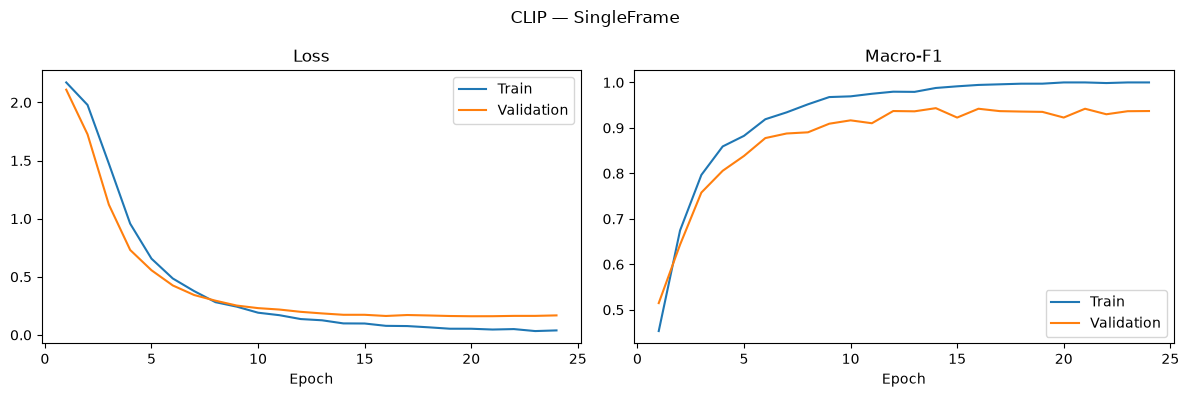


TRAINING: CLIP MeanPooling
clip/MeanPooling | epoch 01 | train loss 2.1714 | val macro-F1 0.5659
clip/MeanPooling | epoch 05 | train loss 0.6750 | val macro-F1 0.8641
clip/MeanPooling | epoch 10 | train loss 0.1801 | val macro-F1 0.9549
clip/MeanPooling | epoch 15 | train loss 0.0856 | val macro-F1 0.9674
clip/MeanPooling | epoch 20 | train loss 0.0501 | val macro-F1 0.9612
Early stopping at epoch 23. Best epoch: 13


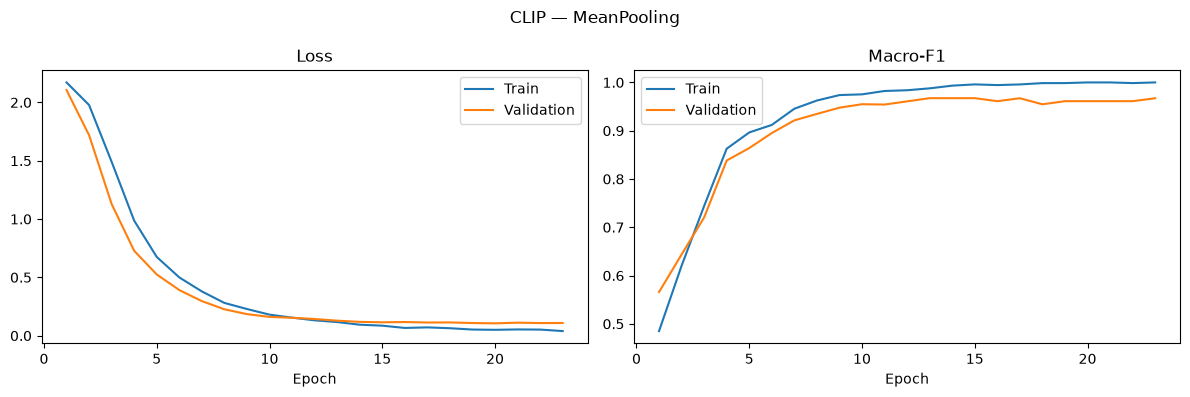


TRAINING: CLIP GRU
clip/GRU | epoch 01 | train loss 2.1795 | val macro-F1 0.2070
clip/GRU | epoch 05 | train loss 0.6485 | val macro-F1 0.7595
clip/GRU | epoch 10 | train loss 0.1320 | val macro-F1 0.9262
clip/GRU | epoch 15 | train loss 0.0307 | val macro-F1 0.9429
clip/GRU | epoch 20 | train loss 0.0067 | val macro-F1 0.9513
Early stopping at epoch 23. Best epoch: 13


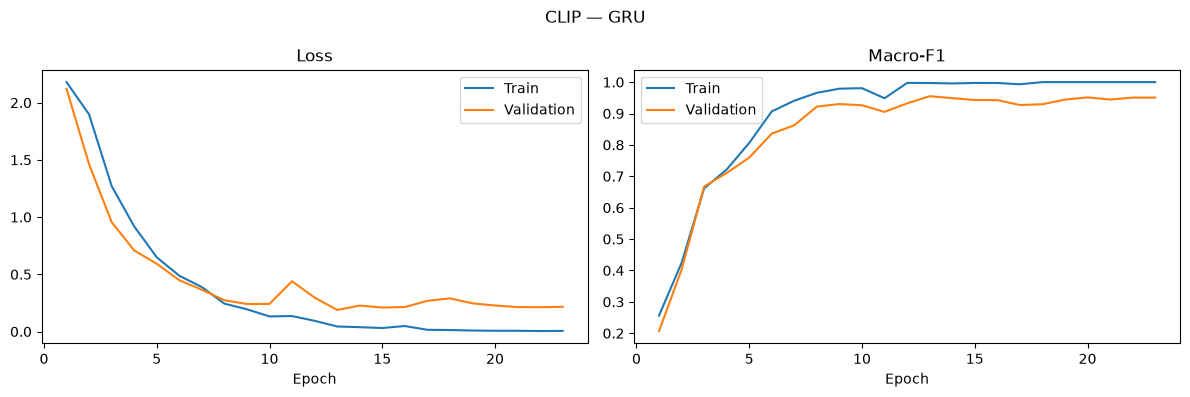


TRAINING: CLIP LSTM
clip/LSTM | epoch 01 | train loss 2.1817 | val macro-F1 0.0865
clip/LSTM | epoch 05 | train loss 0.8645 | val macro-F1 0.7384
clip/LSTM | epoch 10 | train loss 0.2730 | val macro-F1 0.8845
clip/LSTM | epoch 15 | train loss 0.0702 | val macro-F1 0.9175
clip/LSTM | epoch 20 | train loss 0.0093 | val macro-F1 0.9537
clip/LSTM | epoch 25 | train loss 0.0033 | val macro-F1 0.9344
clip/LSTM | epoch 30 | train loss 0.0021 | val macro-F1 0.9411
Early stopping at epoch 32. Best epoch: 22


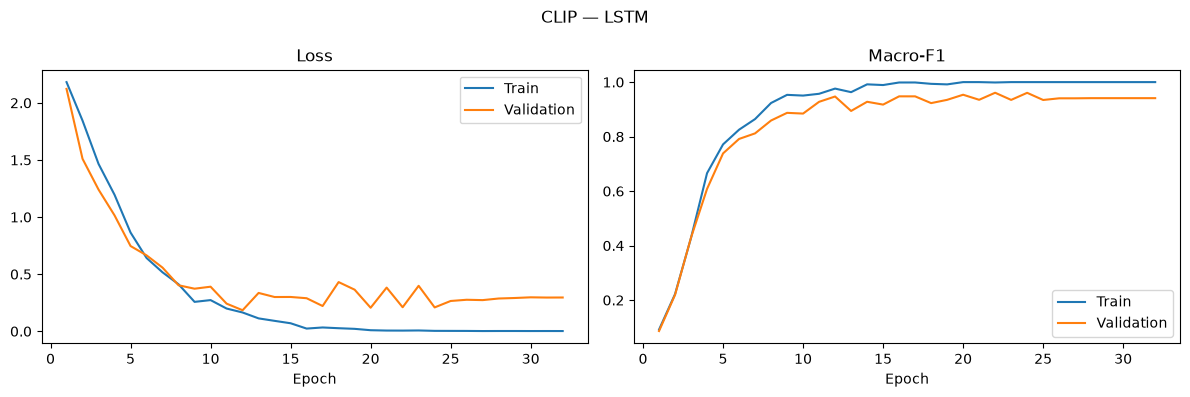


TRAINING: CLIP Transformer_Encoder


/var/folders/yk/975v12617wjby1k2n4krpjp00000gn/T/ipykernel_62684/4034052615.py:65: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(layer, num_layers=2)


clip/Transformer_Encoder | epoch 01 | train loss 1.6528 | val macro-F1 0.7542
clip/Transformer_Encoder | epoch 05 | train loss 0.0598 | val macro-F1 0.9670
clip/Transformer_Encoder | epoch 10 | train loss 0.0884 | val macro-F1 0.9622
clip/Transformer_Encoder | epoch 15 | train loss 0.0027 | val macro-F1 0.9614
clip/Transformer_Encoder | epoch 20 | train loss 0.0012 | val macro-F1 0.9677
Early stopping at epoch 24. Best epoch: 14


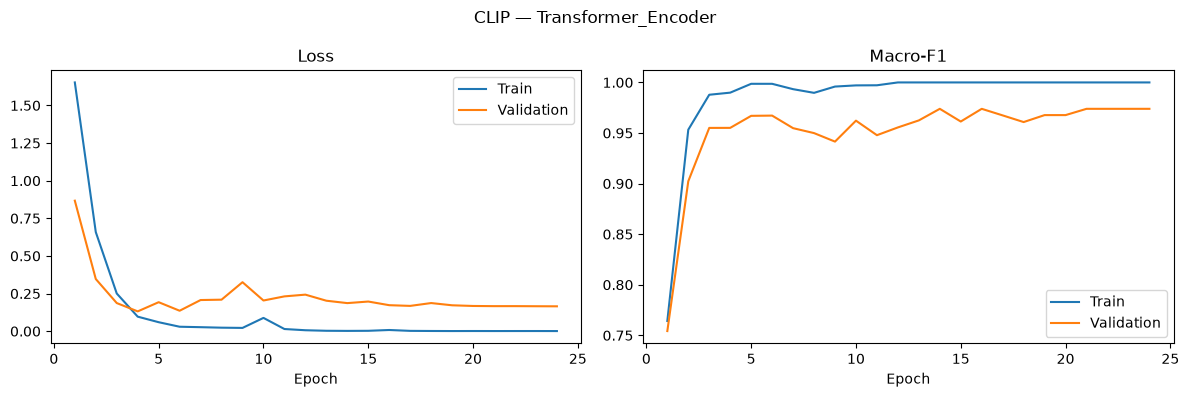


TRAINING: CLIP Temporal_CNN
clip/Temporal_CNN | epoch 01 | train loss 1.4932 | val macro-F1 0.2405
clip/Temporal_CNN | epoch 05 | train loss 0.0872 | val macro-F1 0.9285
clip/Temporal_CNN | epoch 10 | train loss 0.0440 | val macro-F1 0.9620
clip/Temporal_CNN | epoch 15 | train loss 0.0168 | val macro-F1 0.9671
clip/Temporal_CNN | epoch 20 | train loss 0.0206 | val macro-F1 0.9672
clip/Temporal_CNN | epoch 25 | train loss 0.0009 | val macro-F1 0.9675
Early stopping at epoch 28. Best epoch: 18


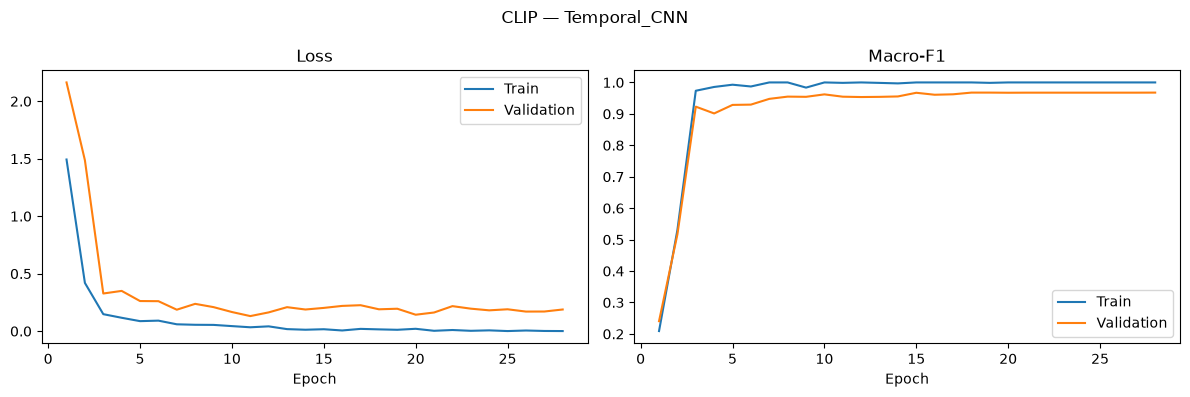


TRAINING: SIGLIP SingleFrame
siglip/SingleFrame | epoch 01 | train loss 2.1653 | val macro-F1 0.3568
siglip/SingleFrame | epoch 05 | train loss 0.6035 | val macro-F1 0.8527
siglip/SingleFrame | epoch 10 | train loss 0.1999 | val macro-F1 0.9001
siglip/SingleFrame | epoch 15 | train loss 0.0848 | val macro-F1 0.9240
siglip/SingleFrame | epoch 20 | train loss 0.0479 | val macro-F1 0.9133
siglip/SingleFrame | epoch 25 | train loss 0.0265 | val macro-F1 0.9146
siglip/SingleFrame | epoch 30 | train loss 0.0181 | val macro-F1 0.9264
siglip/SingleFrame | epoch 35 | train loss 0.0168 | val macro-F1 0.9324
Early stopping at epoch 36. Best epoch: 26


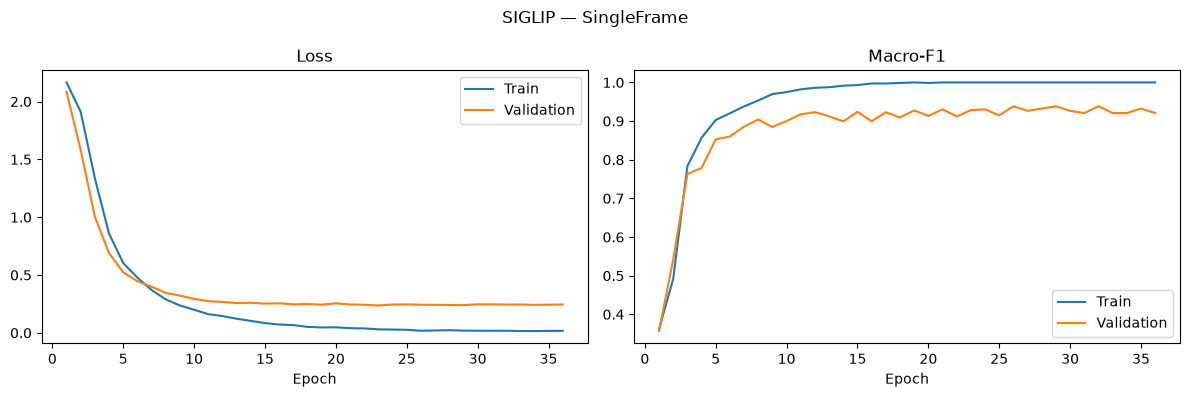


TRAINING: SIGLIP MeanPooling
siglip/MeanPooling | epoch 01 | train loss 2.1637 | val macro-F1 0.4166
siglip/MeanPooling | epoch 05 | train loss 0.5955 | val macro-F1 0.8769
siglip/MeanPooling | epoch 10 | train loss 0.1827 | val macro-F1 0.9431
siglip/MeanPooling | epoch 15 | train loss 0.0780 | val macro-F1 0.9491
siglip/MeanPooling | epoch 20 | train loss 0.0418 | val macro-F1 0.9677
siglip/MeanPooling | epoch 25 | train loss 0.0279 | val macro-F1 0.9611
siglip/MeanPooling | epoch 30 | train loss 0.0232 | val macro-F1 0.9612
Early stopping at epoch 30. Best epoch: 20


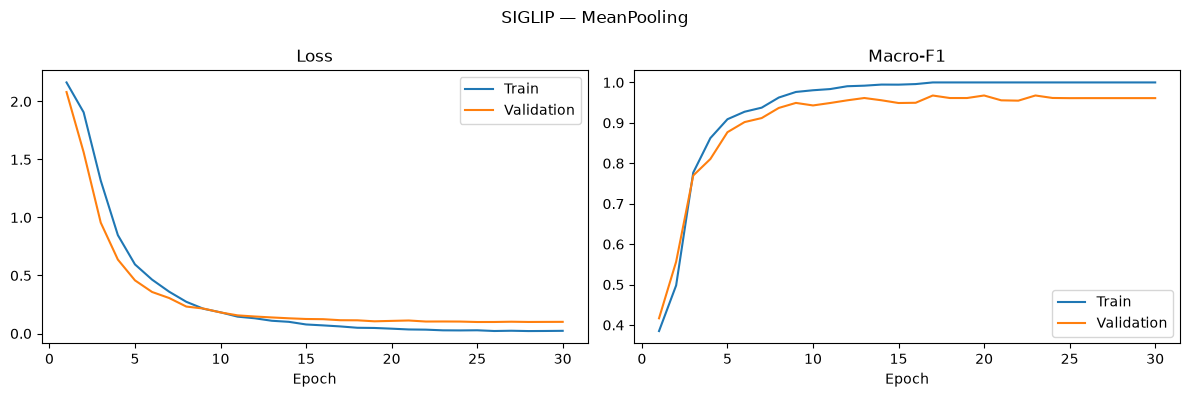


TRAINING: SIGLIP GRU
siglip/GRU | epoch 01 | train loss 2.1698 | val macro-F1 0.5292
siglip/GRU | epoch 05 | train loss 0.4273 | val macro-F1 0.8810
siglip/GRU | epoch 10 | train loss 0.0964 | val macro-F1 0.9033
siglip/GRU | epoch 15 | train loss 0.0166 | val macro-F1 0.9200
siglip/GRU | epoch 20 | train loss 0.0076 | val macro-F1 0.9324
siglip/GRU | epoch 25 | train loss 0.0042 | val macro-F1 0.9205
Early stopping at epoch 28. Best epoch: 18


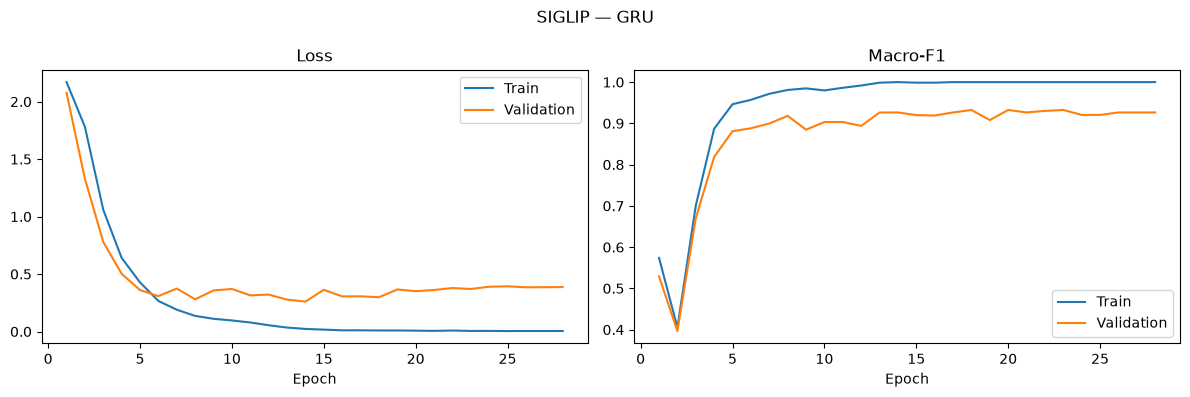


TRAINING: SIGLIP LSTM
siglip/LSTM | epoch 01 | train loss 2.1851 | val macro-F1 0.2337
siglip/LSTM | epoch 05 | train loss 0.6081 | val macro-F1 0.7934
siglip/LSTM | epoch 10 | train loss 0.1347 | val macro-F1 0.8833
siglip/LSTM | epoch 15 | train loss 0.0461 | val macro-F1 0.9297
siglip/LSTM | epoch 20 | train loss 0.0078 | val macro-F1 0.9430
Early stopping at epoch 23. Best epoch: 13


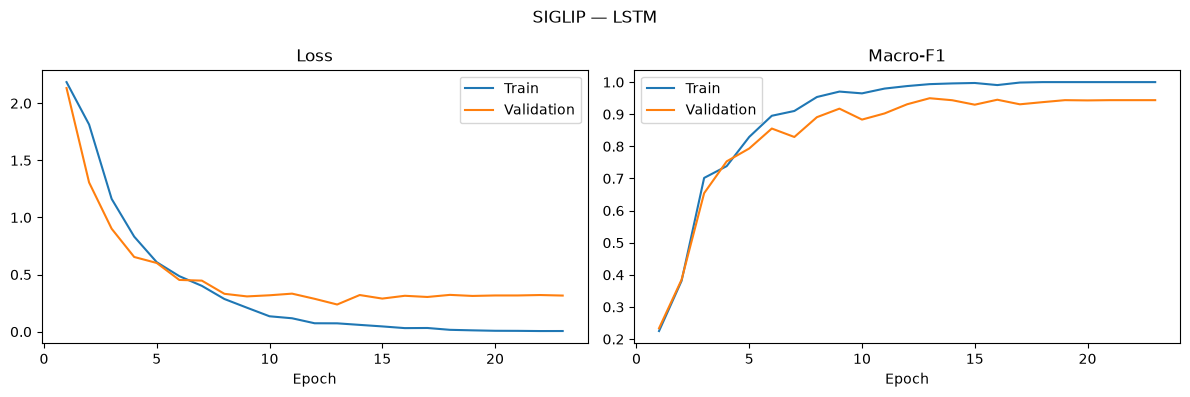


TRAINING: SIGLIP Transformer_Encoder


/var/folders/yk/975v12617wjby1k2n4krpjp00000gn/T/ipykernel_62684/4034052615.py:65: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(layer, num_layers=2)


siglip/Transformer_Encoder | epoch 01 | train loss 1.5740 | val macro-F1 0.8606
siglip/Transformer_Encoder | epoch 05 | train loss 0.0688 | val macro-F1 0.9699
siglip/Transformer_Encoder | epoch 10 | train loss 0.0067 | val macro-F1 0.9560
siglip/Transformer_Encoder | epoch 15 | train loss 0.0020 | val macro-F1 0.9620
Early stopping at epoch 15. Best epoch: 5


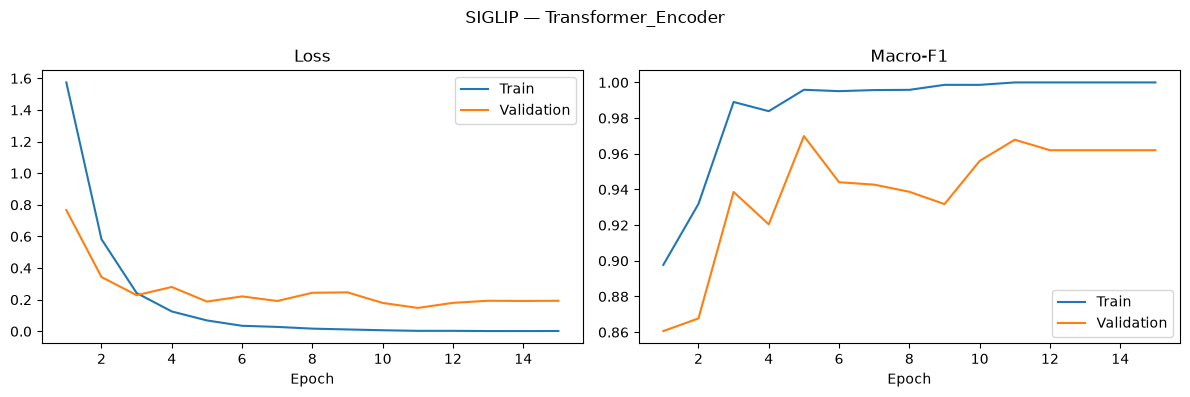


TRAINING: SIGLIP Temporal_CNN
siglip/Temporal_CNN | epoch 01 | train loss 1.3131 | val macro-F1 0.1221
siglip/Temporal_CNN | epoch 05 | train loss 0.1208 | val macro-F1 0.9247
siglip/Temporal_CNN | epoch 10 | train loss 0.0996 | val macro-F1 0.9371
siglip/Temporal_CNN | epoch 15 | train loss 0.0469 | val macro-F1 0.9442
siglip/Temporal_CNN | epoch 20 | train loss 0.0030 | val macro-F1 0.9568
siglip/Temporal_CNN | epoch 25 | train loss 0.0023 | val macro-F1 0.9503
Early stopping at epoch 27. Best epoch: 17


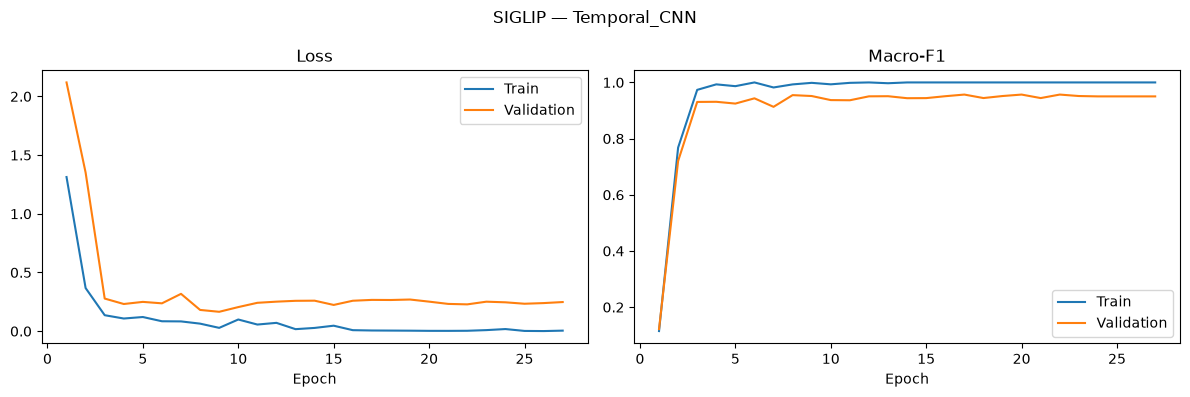

Training completed for 12 models.


In [10]:
MODEL_SPECS = [
    ("SingleFrame", "single"),
    ("MeanPooling", "mean"),
    ("GRU", "sequence"),
    ("LSTM", "sequence"),
    ("Transformer_Encoder", "sequence"),
    ("Temporal_CNN", "sequence"),
]

TRAINED_MODELS = {}
EXPERIMENT_META = []

for encoder, records in VIDEO_RECORDS.items():
    train_records = make_records_for_split(records, "train")
    val_records = make_records_for_split(records, "validation")

    for model_name, mode in MODEL_SPECS:
        if model_name == "SingleFrame":
            out_dir = BASELINE_ROOT / encoder / "SingleFrame"
        elif model_name == "MeanPooling":
            out_dir = BASELINE_ROOT / encoder / "MeanPooling_Control"
        elif model_name == "GRU":
            out_dir = TEMPORAL_ROOT / "GRU" / encoder
        elif model_name == "LSTM":
            out_dir = TEMPORAL_ROOT / "LSTM" / encoder
        elif model_name == "Transformer_Encoder":
            out_dir = TEMPORAL_ROOT / "Transformer_Encoder" / encoder
        else:
            out_dir = TEMPORAL_ROOT / "Temporal_CNN" / encoder

        print("\n" + "=" * 80)
        print("TRAINING:", encoder.upper(), model_name)
        model, meta = train_experiment(
            encoder, model_name, mode, train_records, val_records, out_dir
        )
        TRAINED_MODELS[(encoder, model_name)] = model
        EXPERIMENT_META.append(meta)

        pd.DataFrame(EXPERIMENT_META).to_csv(
            EVALUATION_ROOT / "training_experiment_metadata.csv", index=False
        )

print("Training completed for", len(TRAINED_MODELS), "models.")

## 10. Final test evaluation

Each trained model is evaluated exactly once on the held-out test videos. We save raw predictions and class probabilities so later analyses do not require rerunning inference.

For temporal models, we also evaluate a shuffled-order version of each test sequence using the same trained weights. The shuffled test order is generated with a fixed seed for reproducibility.

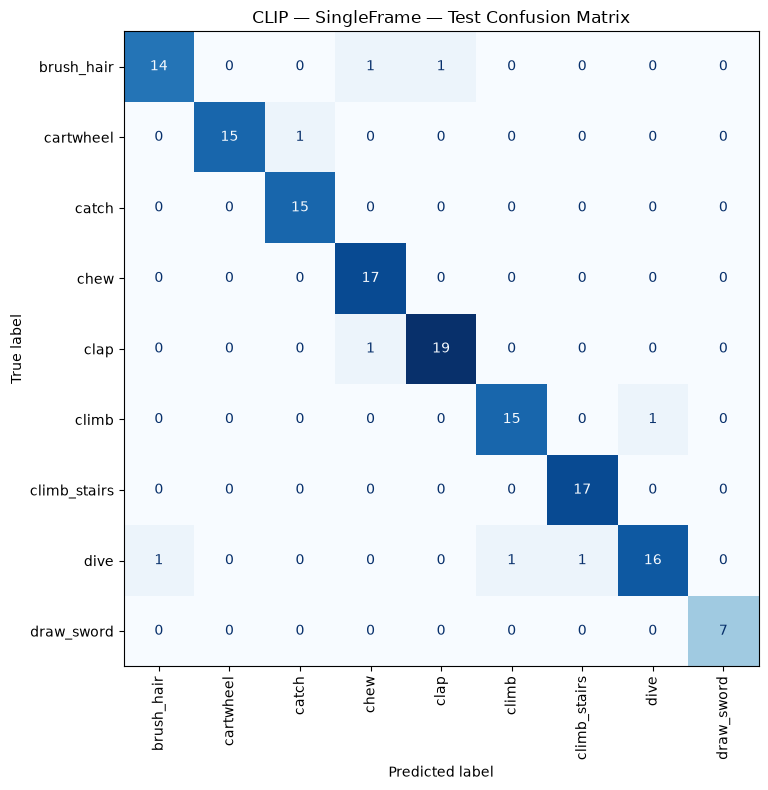

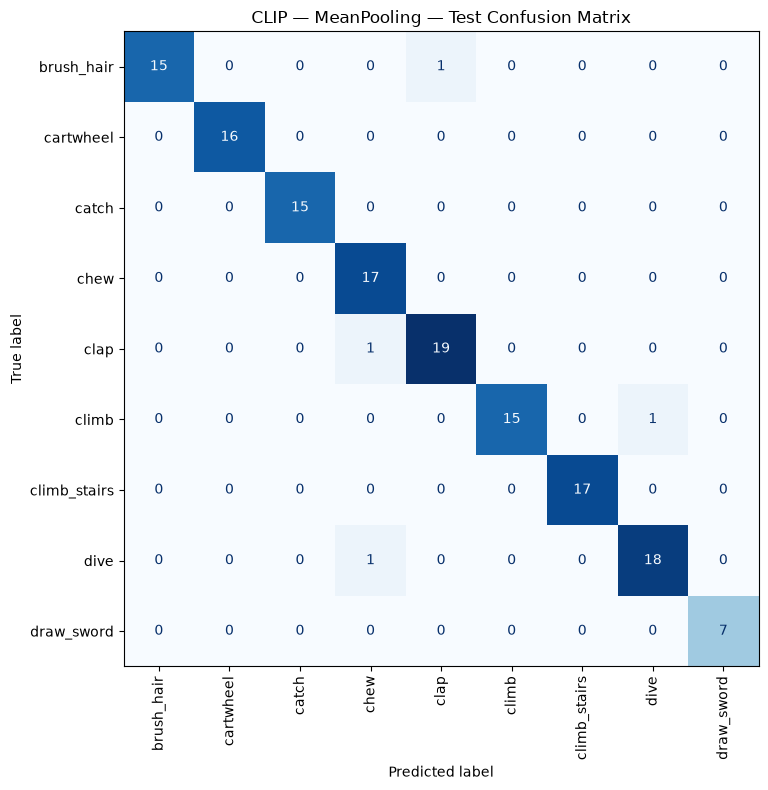

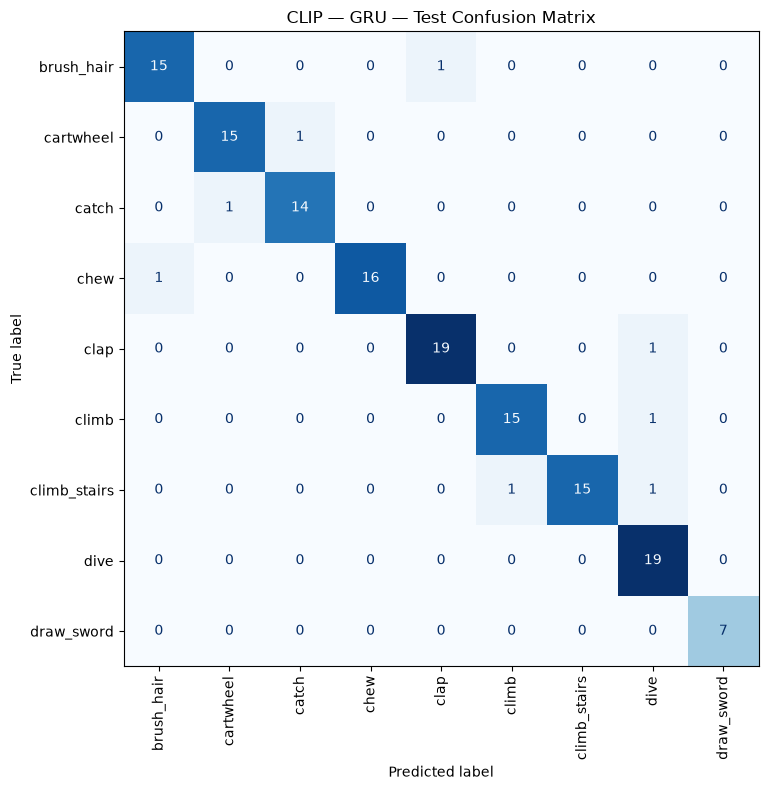

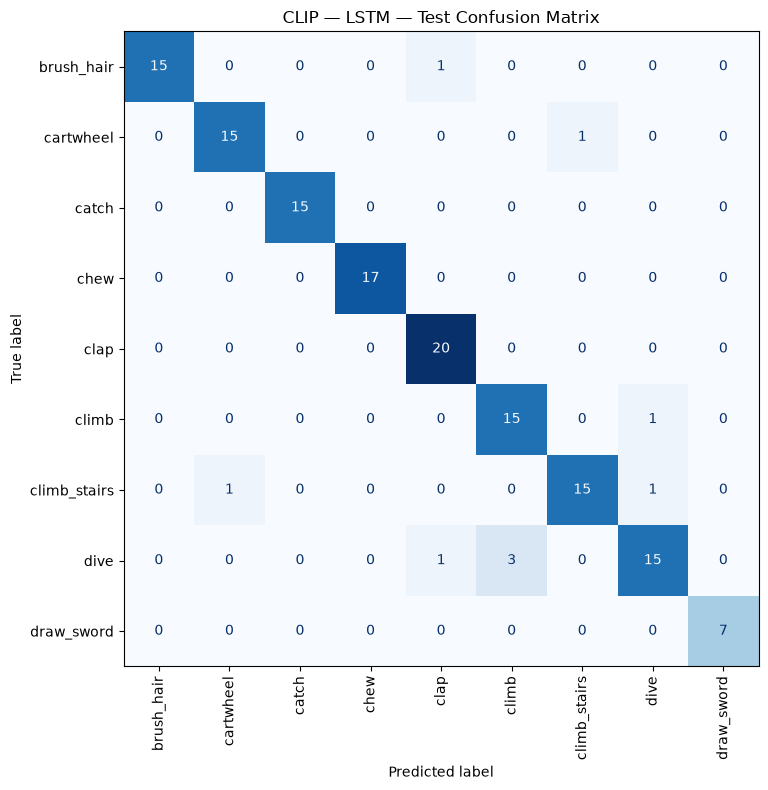

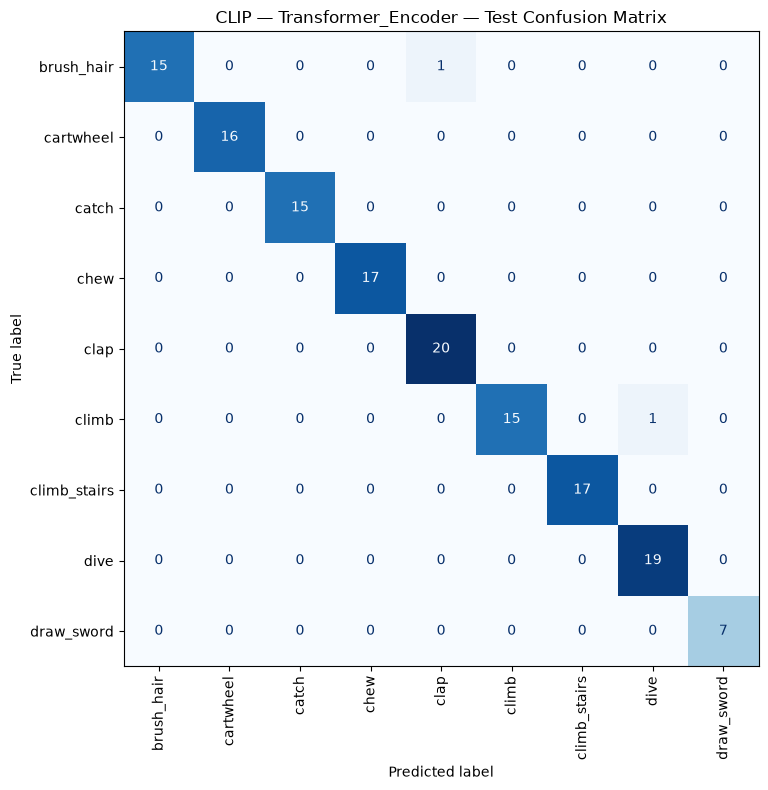

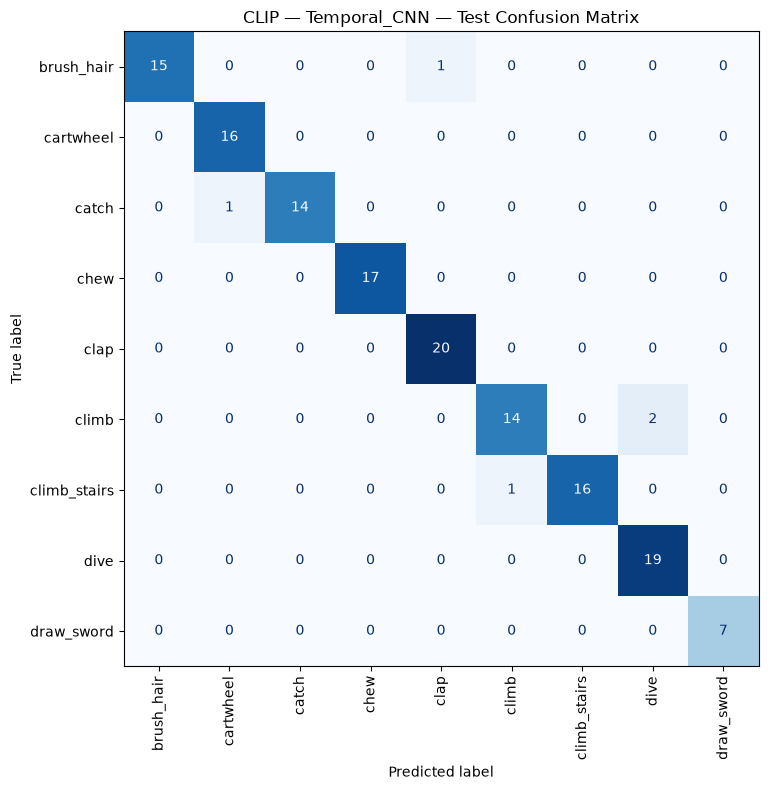

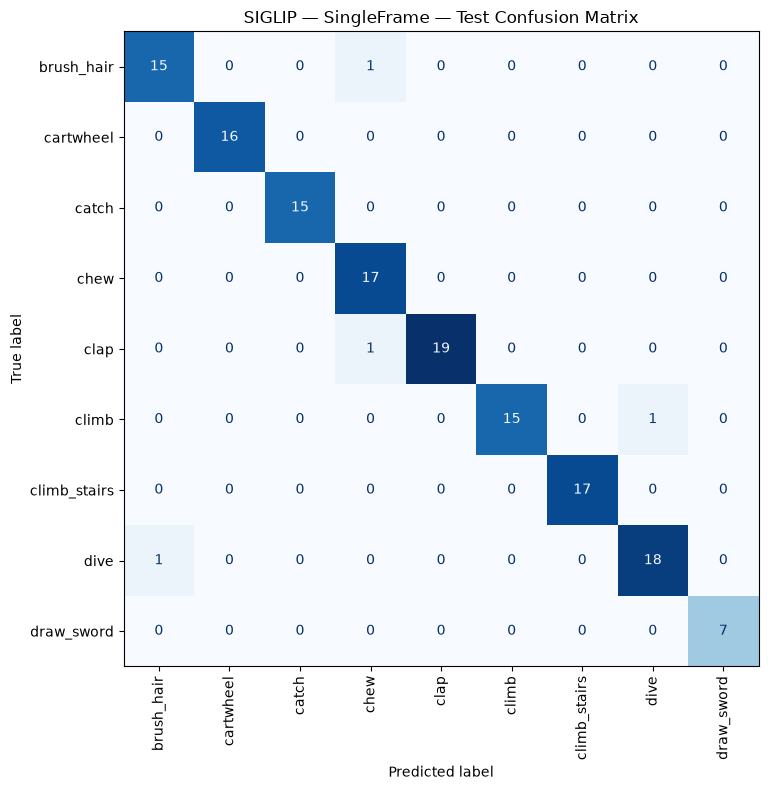

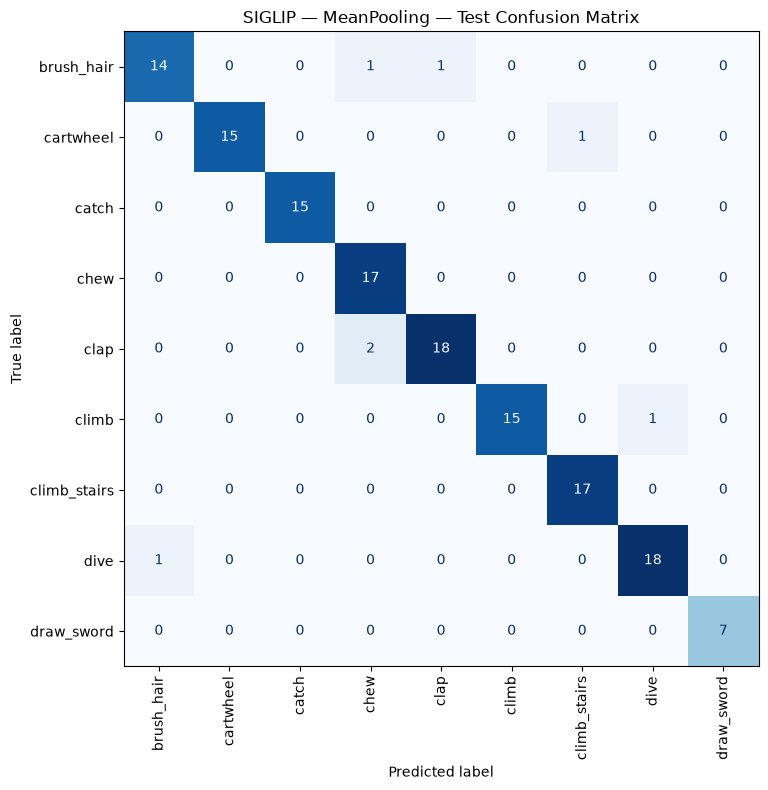

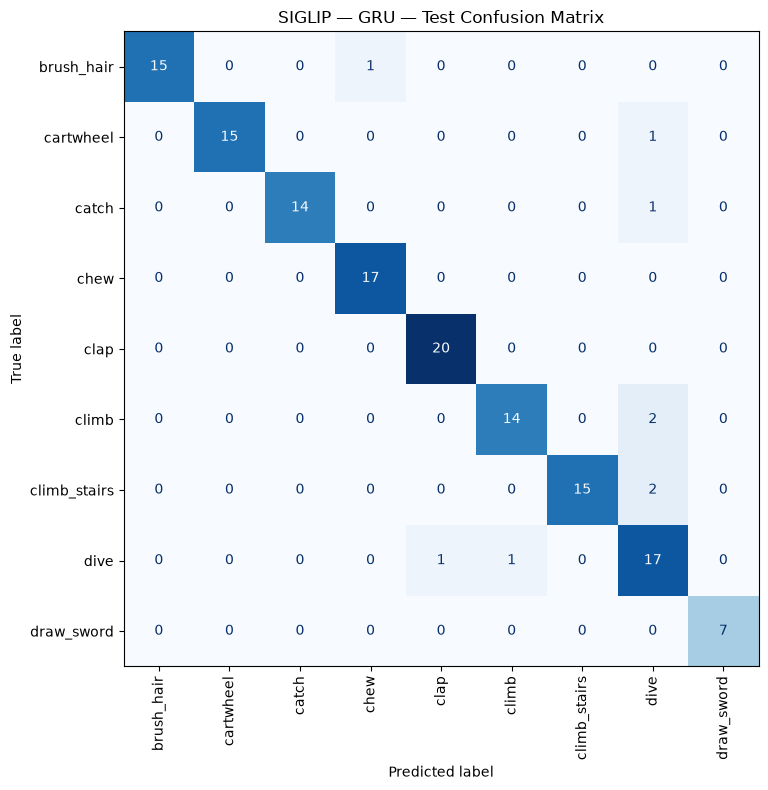

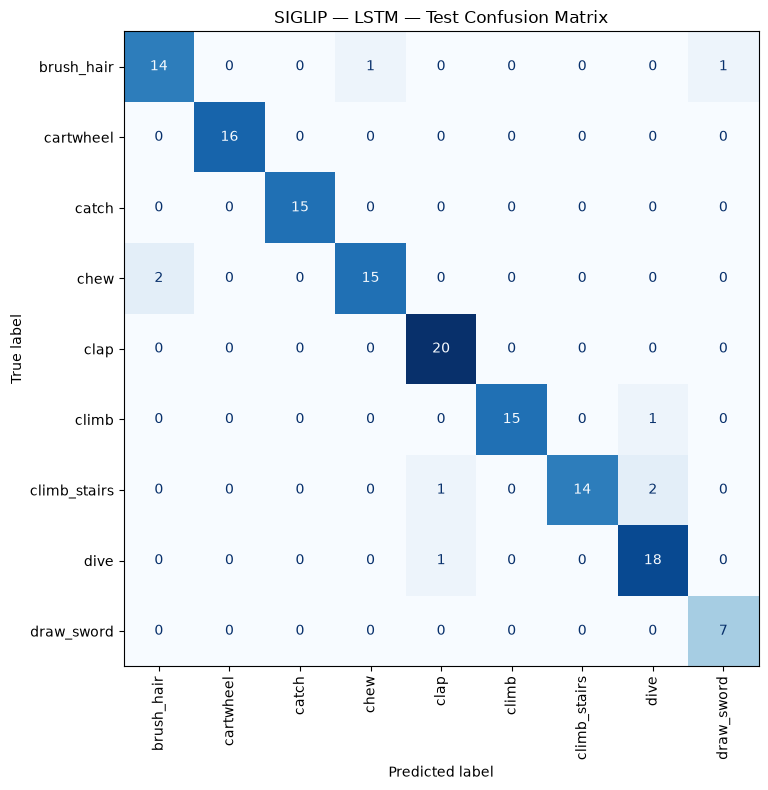

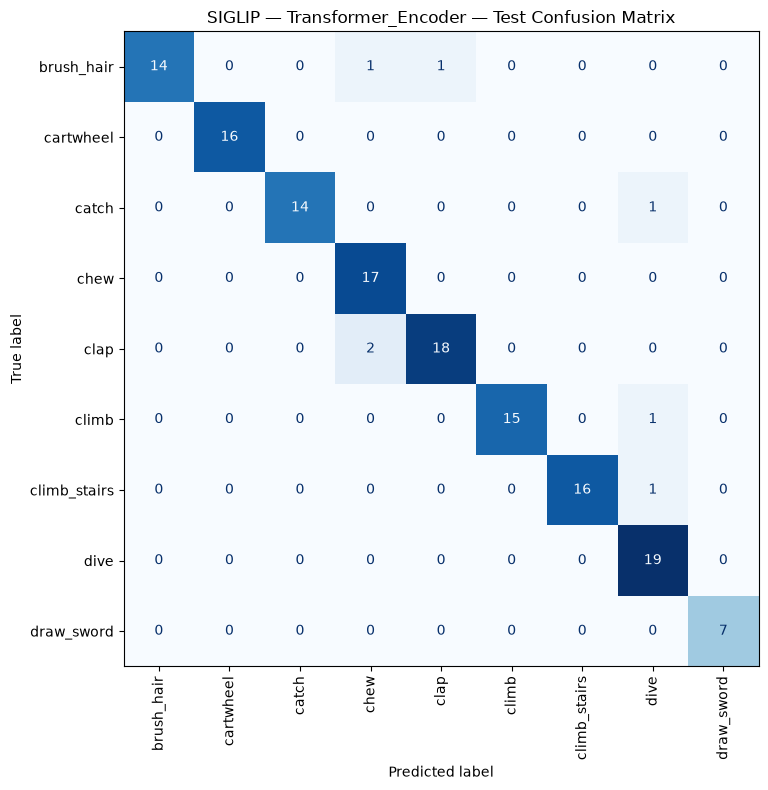

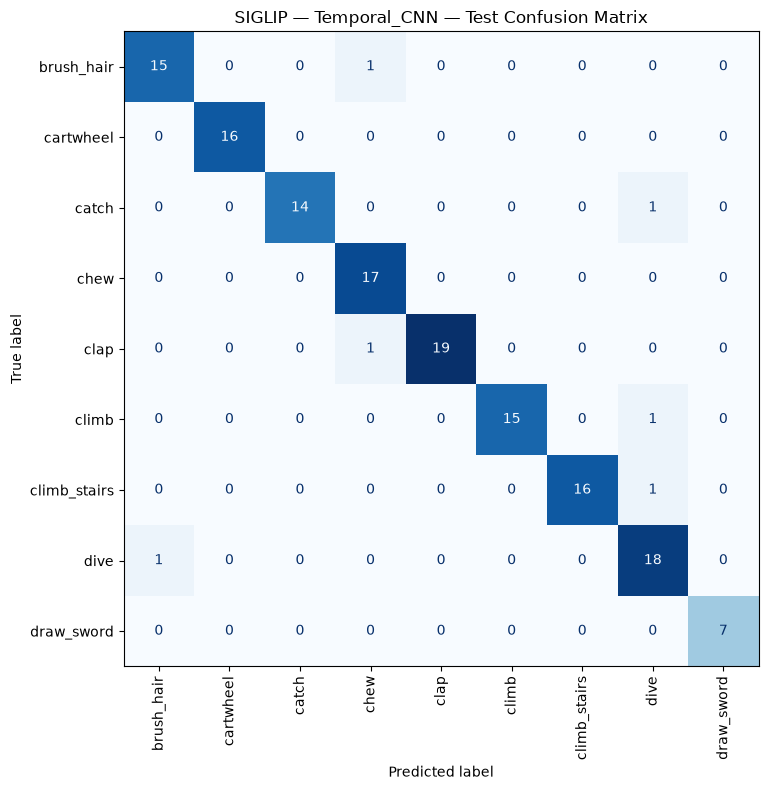

,encoder,model,split,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,loss,best_epoch,trainable_parameters,shuffled_order_accuracy,shuffled_order_macro_f1,order_sensitivity_macro_f1_drop,shuffled_order_predictions_saved
4,clip,Transformer_Encoder,test,0.986014,0.989153,0.986111,0.987273,0.985963,None,14,343817,0.986014,0.987273,0.000000,True
1,clip,MeanPooling,test,0.972028,0.976901,0.974708,0.975255,0.972191,None,13,165385,NaN,NaN,NaN,NaN
5,clip,Temporal_CNN,test,0.965035,0.970184,0.965223,0.966832,0.964898,None,18,272649,0.972028,0.973131,-0.006299,True
0,clip,SingleFrame,test,0.944056,0.948743,0.949123,0.947886,0.943429,None,14,165385,NaN,NaN,NaN,NaN
2,clip,GRU,test,0.944056,0.951052,0.946596,0.947762,0.944280,None,13,173577,0.937063,0.941502,0.006260,True
3,clip,LSTM,test,0.937063,0.944420,0.942703,0.942489,0.936622,None,22,206601,0.944056,0.948963,-0.006474,True
6,siglip,SingleFrame,test,0.972028,0.975512,0.974708,0.974602,0.972214,None,26,230921,NaN,NaN,NaN,NaN
11,siglip,Temporal_CNN,test,0.958042,0.965487,0.960764,0.962140,0.958701,None,17,305417,0.965035,0.968357,-0.006217,True
10,siglip,Transformer_Encoder,test,0.951049,0.962334,0.954112,0.956124,0.951593,None,5,376585,0.951049,0.956124,0.000000,True
7,siglip,MeanPooling,test,0.951049,0.958057,0.955263,0.955500,0.951166,None,20,230921,NaN,NaN,NaN,NaN


In [11]:
def get_output_dir(encoder, model_name):
    if model_name == "SingleFrame":
        return BASELINE_ROOT / encoder / "SingleFrame"
    if model_name == "MeanPooling":
        return BASELINE_ROOT / encoder / "MeanPooling_Control"
    folder = {
        "GRU": "GRU",
        "LSTM": "LSTM",
        "Transformer_Encoder": "Transformer_Encoder",
        "Temporal_CNN": "Temporal_CNN",
    }[model_name]
    return TEMPORAL_ROOT / folder / encoder

TEST_RESULTS = {}
test_records_by_encoder = {
    enc: make_records_for_split(recs, "test")
    for enc, recs in VIDEO_RECORDS.items()
}

for (encoder, model_name), model in TRAINED_MODELS.items():
    mode = dict(MODEL_SPECS)[model_name]
    test_loader = make_loader(test_records_by_encoder[encoder], shuffle=False)
    out_dir = get_output_dir(encoder, model_name)

    metrics, y_true, y_pred, probs, video_ids = evaluate_loader(
        model, test_loader, mode
    )

    pred_df = pd.DataFrame({
        "video_id": video_ids,
        "y_true_id": y_true,
        "y_true": [ID_TO_LABEL[int(x)] for x in y_true],
        "y_pred_id": y_pred,
        "y_pred": [ID_TO_LABEL[int(x)] for x in y_pred],
        "correct": y_true == y_pred,
        "max_probability": probs.max(axis=1),
    })
    pred_df.to_csv(out_dir / "test_predictions.csv", index=False)
    np.save(out_dir / "test_probabilities.npy", probs)

    report = classification_report(
        y_true, y_pred, labels=list(range(NUM_CLASSES)),
        target_names=LABELS, output_dict=True, zero_division=0
    )
    (out_dir / "classification_report.json").write_text(
        json.dumps(report, indent=2)
    )

    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    pd.DataFrame(cm, index=LABELS, columns=LABELS).to_csv(
        out_dir / "confusion_matrix.csv"
    )
    fig, ax = plt.subplots(figsize=(9, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=LABELS)
    disp.plot(ax=ax, xticks_rotation=90, colorbar=False, cmap="Blues")
    ax.set_title(f"{encoder.upper()} — {model_name} — Test Confusion Matrix")
    fig.tight_layout()
    fig.savefig(out_dir / "confusion_matrix.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    result = {
        "encoder": encoder,
        "model": model_name,
        "split": "test",
        **metrics,
        "best_epoch": next(
            x["best_epoch"] for x in EXPERIMENT_META
            if x["encoder"] == encoder and x["model"] == model_name
        ),
        "trainable_parameters": count_parameters(model),
    }

    # Shuffled order is meaningful only for models that consume sequences.
    if mode == "sequence":
        set_seed(SEED + 100)
        shuffled_metrics, sy, sp, sprob, sids = evaluate_loader(
            model, test_loader, mode, shuffle_order=True
        )
        result["shuffled_order_accuracy"] = shuffled_metrics["accuracy"]
        result["shuffled_order_macro_f1"] = shuffled_metrics["macro_f1"]
        result["order_sensitivity_macro_f1_drop"] = (
            metrics["macro_f1"] - shuffled_metrics["macro_f1"]
        )
        shuffled_df = pd.DataFrame({
            "video_id": sids,
            "y_true": [ID_TO_LABEL[int(x)] for x in sy],
            "y_pred": [ID_TO_LABEL[int(x)] for x in sp],
            "correct": sy == sp,
        })
        shuffled_df.to_csv(out_dir / "shuffled_order_test_predictions.csv", index=False)
        result["shuffled_order_predictions_saved"] = True
    else:
        result["shuffled_order_accuracy"] = np.nan
        result["shuffled_order_macro_f1"] = np.nan
        result["order_sensitivity_macro_f1_drop"] = np.nan

    TEST_RESULTS[(encoder, model_name)] = result

test_results_df = pd.DataFrame(TEST_RESULTS.values())
test_results_df.to_csv(EVALUATION_ROOT / "test_metrics_all_models.csv", index=False)
display(test_results_df.sort_values(["encoder", "macro_f1"], ascending=[True, False]))

## 11. Architecture comparison

This section creates separate comparisons for CLIP and SigLIP, then a combined table. The primary metric is **test macro-F1**; accuracy is reported alongside it.

The single-frame baseline is the primary static comparison. Mean pooling is a useful multi-frame, order-agnostic control. GRU/LSTM/Transformer/Temporal CNN are the learned temporal approaches.

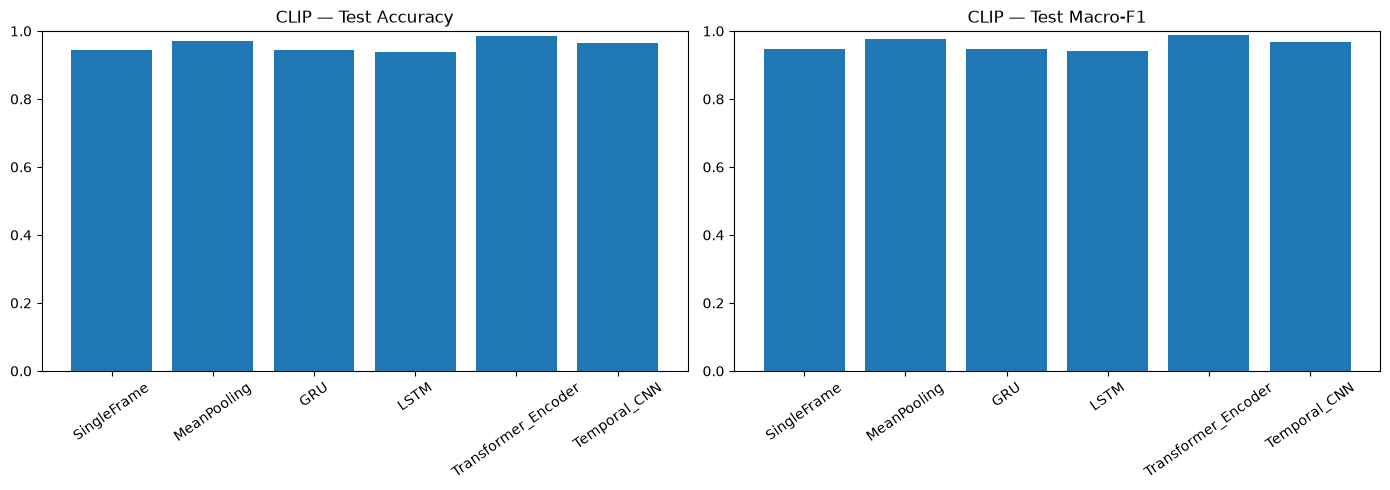

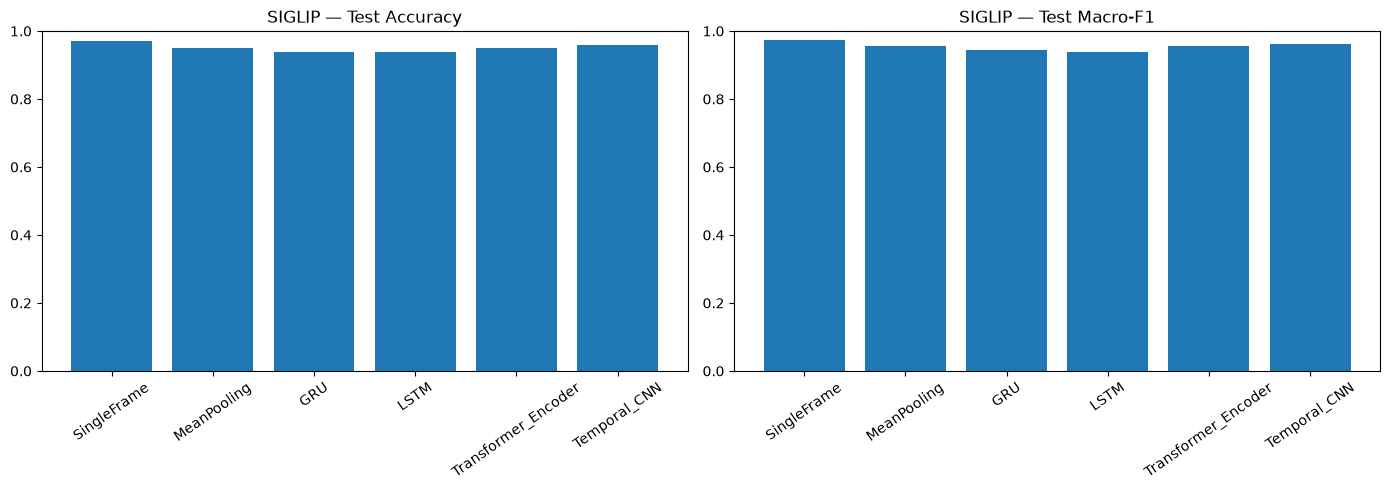

encoder,clip,siglip
model,,
GRU,0.947762,0.944254
LSTM,0.942489,0.937864
MeanPooling,0.975255,0.955500
SingleFrame,0.947886,0.974602
Temporal_CNN,0.966832,0.962140
Transformer_Encoder,0.987273,0.956124


In [12]:
MODEL_DISPLAY_ORDER = [
    "SingleFrame", "MeanPooling", "GRU", "LSTM",
    "Transformer_Encoder", "Temporal_CNN"
]

for encoder in ENCODER_CONFIG:
    subset = test_results_df[test_results_df["encoder"] == encoder].copy()
    subset["model"] = pd.Categorical(
        subset["model"], categories=MODEL_DISPLAY_ORDER, ordered=True
    )
    subset = subset.sort_values("model")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].bar(subset["model"].astype(str), subset["accuracy"])
    axes[0].set_title(f"{encoder.upper()} — Test Accuracy")
    axes[0].set_ylim(0, 1)
    axes[0].tick_params(axis="x", rotation=35)

    axes[1].bar(subset["model"].astype(str), subset["macro_f1"])
    axes[1].set_title(f"{encoder.upper()} — Test Macro-F1")
    axes[1].set_ylim(0, 1)
    axes[1].tick_params(axis="x", rotation=35)

    fig.tight_layout()
    fig.savefig(
        EVALUATION_ROOT / f"{encoder}_architecture_comparison.png",
        dpi=160, bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

display(test_results_df.pivot(index="model", columns="encoder", values="macro_f1"))

## 12. Order-sensitivity analysis

A temporal model can exploit frame order, but it may also classify mostly from the set of frames regardless of order. Compare original-order and shuffled-order test macro-F1.

A larger positive drop suggests greater dependence on chronological ordering. A small drop does not automatically mean the model failed: the sampled frames may already contain enough appearance information, or the action may be recognizable without precise order.

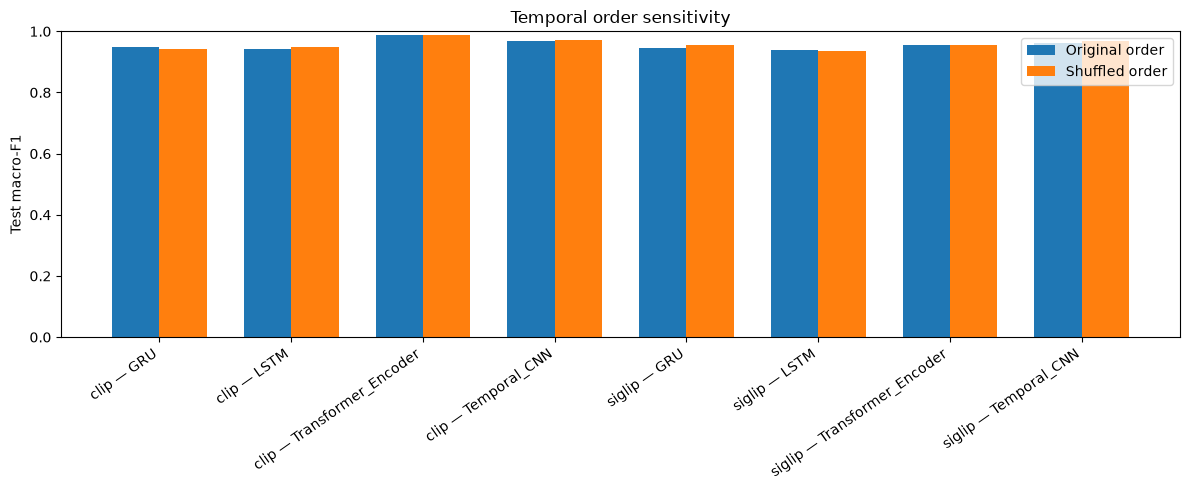

,encoder,model,macro_f1,shuffled_order_macro_f1,order_sensitivity_macro_f1_drop
2,clip,GRU,0.947762,0.941502,0.006260
9,siglip,LSTM,0.937864,0.937009,0.000854
4,clip,Transformer_Encoder,0.987273,0.987273,0.000000
10,siglip,Transformer_Encoder,0.956124,0.956124,0.000000
11,siglip,Temporal_CNN,0.962140,0.968357,-0.006217
5,clip,Temporal_CNN,0.966832,0.973131,-0.006299
3,clip,LSTM,0.942489,0.948963,-0.006474
8,siglip,GRU,0.944254,0.956714,-0.012459


In [13]:
temporal_results = test_results_df[
    test_results_df["model"].isin(
        ["GRU", "LSTM", "Transformer_Encoder", "Temporal_CNN"]
    )
].copy()

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(temporal_results))
width = 0.36
ax.bar(
    x - width/2, temporal_results["macro_f1"], width,
    label="Original order"
)
ax.bar(
    x + width/2, temporal_results["shuffled_order_macro_f1"], width,
    label="Shuffled order"
)
ax.set_xticks(x)
ax.set_xticklabels(
    temporal_results["encoder"] + " — " + temporal_results["model"],
    rotation=35, ha="right"
)
ax.set_ylim(0, 1)
ax.set_ylabel("Test macro-F1")
ax.set_title("Temporal order sensitivity")
ax.legend()
fig.tight_layout()
fig.savefig(EVALUATION_ROOT / "temporal_order_sensitivity.png",
            dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

display(temporal_results[[
    "encoder", "model", "macro_f1",
    "shuffled_order_macro_f1", "order_sensitivity_macro_f1_drop"
]].sort_values("order_sensitivity_macro_f1_drop", ascending=False))

## 13. Per-class analysis and error inspection

Aggregate scores can hide classes that benefit from temporal context. This cell combines per-class reports and lists videos misclassified by each approach. Use the saved prediction CSVs to inspect individual examples alongside the original frame strips from Notebook 01.

In [14]:
per_class_rows = []
error_rows = []

for (encoder, model_name), model in TRAINED_MODELS.items():
    out_dir = get_output_dir(encoder, model_name)
    report = json.loads((out_dir / "classification_report.json").read_text())
    for label in LABELS:
        values = report[label]
        per_class_rows.append({
            "encoder": encoder,
            "model": model_name,
            "class": label,
            "precision": values["precision"],
            "recall": values["recall"],
            "f1": values["f1-score"],
            "support": values["support"],
        })

    pred_df = pd.read_csv(out_dir / "test_predictions.csv")
    errors = pred_df[~pred_df["correct"]].copy()
    errors["encoder"] = encoder
    errors["model"] = model_name
    error_rows.append(errors)

per_class_df = pd.DataFrame(per_class_rows)
errors_df = pd.concat(error_rows, ignore_index=True) if error_rows else pd.DataFrame()
per_class_df.to_csv(EVALUATION_ROOT / "per_class_metrics.csv", index=False)
errors_df.to_csv(EVALUATION_ROOT / "misclassified_test_videos.csv", index=False)

display(per_class_df.sort_values(["encoder", "class", "f1"]))
print("Total saved error rows:", len(errors_df))

,encoder,model,class,precision,recall,f1,support
0,clip,SingleFrame,brush_hair,0.933333,0.8750,0.903226,16.0
18,clip,GRU,brush_hair,0.937500,0.9375,0.937500,16.0
9,clip,MeanPooling,brush_hair,1.000000,0.9375,0.967742,16.0
27,clip,LSTM,brush_hair,1.000000,0.9375,0.967742,16.0
36,clip,Transformer_Encoder,brush_hair,1.000000,0.9375,0.967742,16.0
...,...,...,...,...,...,...,...
62,siglip,SingleFrame,draw_sword,1.000000,1.0000,1.000000,7.0
71,siglip,MeanPooling,draw_sword,1.000000,1.0000,1.000000,7.0
80,siglip,GRU,draw_sword,1.000000,1.0000,1.000000,7.0
98,siglip,Transformer_Encoder,draw_sword,1.000000,1.0000,1.000000,7.0


Total saved error rows: 78


## 14. Runtime and model complexity comparison

Parameter counts and training time are recorded for each model. The inference timing below measures the full test loader and is therefore a dataset-level throughput estimate, not a carefully isolated per-video latency benchmark.

In [15]:
runtime_rows = []
for (encoder, model_name), model in TRAINED_MODELS.items():
    mode = dict(MODEL_SPECS)[model_name]
    loader = make_loader(test_records_by_encoder[encoder], shuffle=False)

    # Warm-up
    model.eval()
    with torch.no_grad():
        for i, (x, lengths, y, _) in enumerate(loader):
            x, lengths = x.to(DEVICE), lengths.to(DEVICE)
            _ = forward_for_mode(model, x, lengths, mode)
            if i >= 1:
                break

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        for x, lengths, y, _ in loader:
            x, lengths = x.to(DEVICE), lengths.to(DEVICE)
            _ = forward_for_mode(model, x, lengths, mode)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    meta = next(
        x for x in EXPERIMENT_META
        if x["encoder"] == encoder and x["model"] == model_name
    )
    runtime_rows.append({
        "encoder": encoder,
        "model": model_name,
        "trainable_parameters": count_parameters(model),
        "training_seconds": meta["training_seconds"],
        "test_inference_seconds": elapsed,
        "test_videos": len(test_records_by_encoder[encoder]),
        "inference_ms_per_video": 1000 * elapsed / len(test_records_by_encoder[encoder]),
    })

runtime_df = pd.DataFrame(runtime_rows)
runtime_df.to_csv(EVALUATION_ROOT / "runtime_and_complexity.csv", index=False)
display(runtime_df)

,encoder,model,trainable_parameters,training_seconds,test_inference_seconds,test_videos,inference_ms_per_video
0,clip,SingleFrame,165385,7.314351,0.008149,143,0.056987
1,clip,MeanPooling,165385,5.004177,0.009037,143,0.063194
2,clip,GRU,173577,11.445058,0.025154,143,0.175903
3,clip,LSTM,206601,14.545986,0.025282,143,0.176800
4,clip,Transformer_Encoder,343817,15.016393,0.018963,143,0.132611
5,clip,Temporal_CNN,272649,20.337234,0.046186,143,0.322980
6,siglip,SingleFrame,230921,7.071998,0.008156,143,0.057034
7,siglip,MeanPooling,230921,6.004861,0.008881,143,0.062103
8,siglip,GRU,206345,11.405057,0.024146,143,0.168856
9,siglip,LSTM,239369,9.694385,0.028484,143,0.199187


## 15. Statistical comparison and experiment summary

The held-out test set is relatively small. Report absolute differences in percentage points and avoid claiming statistical significance from a single split. For stronger evidence, a later extension can repeat the experiment across multiple video-level seeds or use paired bootstrap confidence intervals over test videos.

This cell computes:
- best temporal model per encoder;
- improvement over the single-frame baseline;
- improvement over mean pooling;
- best temporal model's shuffled-order drop.

In [16]:
summary_rows = []
for encoder in ENCODER_CONFIG:
    sub = test_results_df[test_results_df["encoder"] == encoder].copy()
    baseline = sub[sub["model"] == "SingleFrame"].iloc[0]
    mean_control = sub[sub["model"] == "MeanPooling"].iloc[0]
    temporal = sub[sub["model"].isin(
        ["GRU", "LSTM", "Transformer_Encoder", "Temporal_CNN"]
    )]
    best = temporal.sort_values("macro_f1", ascending=False).iloc[0]

    summary_rows.append({
        "encoder": encoder,
        "single_frame_accuracy": baseline["accuracy"],
        "single_frame_macro_f1": baseline["macro_f1"],
        "mean_pooling_macro_f1": mean_control["macro_f1"],
        "best_temporal_model": best["model"],
        "best_temporal_accuracy": best["accuracy"],
        "best_temporal_macro_f1": best["macro_f1"],
        "temporal_minus_single_macro_f1": (
            best["macro_f1"] - baseline["macro_f1"]
        ),
        "temporal_minus_mean_pool_macro_f1": (
            best["macro_f1"] - mean_control["macro_f1"]
        ),
        "best_temporal_shuffled_macro_f1": best["shuffled_order_macro_f1"],
        "best_temporal_order_drop": best["order_sensitivity_macro_f1_drop"],
    })

experiment_summary = pd.DataFrame(summary_rows)
display(experiment_summary)
experiment_summary.to_csv(EVALUATION_ROOT / "final_experiment_summary.csv", index=False)

# Compact cross-encoder model comparison.
cross_encoder = test_results_df.pivot_table(
    index="model", columns="encoder",
    values=["accuracy", "macro_f1", "weighted_f1"]
)
cross_encoder.to_csv(EVALUATION_ROOT / "cross_encoder_comparison.csv")
display(cross_encoder)

,encoder,single_frame_accuracy,single_frame_macro_f1,mean_pooling_macro_f1,best_temporal_model,best_temporal_accuracy,best_temporal_macro_f1,temporal_minus_single_macro_f1,temporal_minus_mean_pool_macro_f1,best_temporal_shuffled_macro_f1,best_temporal_order_drop
0,clip,0.944056,0.947886,0.975255,Transformer_Encoder,0.986014,0.987273,0.039387,0.012017,0.987273,0.000000
1,siglip,0.972028,0.974602,0.955500,Temporal_CNN,0.958042,0.962140,-0.012462,0.006640,0.968357,-0.006217


accuracy            macro_f1           weighted_f1  \
encoder                  clip    siglip      clip    siglip        clip   
model                                                                     
GRU                  0.944056  0.937063  0.947762  0.944254    0.944280   
LSTM                 0.937063  0.937063  0.942489  0.937864    0.936622   
MeanPooling          0.972028  0.951049  0.975255  0.955500    0.972191   
SingleFrame          0.944056  0.972028  0.947886  0.974602    0.943429   
Temporal_CNN         0.965035  0.958042  0.966832  0.962140    0.964898   
Transformer_Encoder  0.986014  0.951049  0.987273  0.956124    0.985963   

                               
encoder                siglip  
model                          
GRU                  0.938791  
LSTM                 0.936883  
MeanPooling          0.951166  
SingleFrame          0.972214  
Temporal_CNN         0.958701  
Transformer_Encoder  0.951593

## 16. Save complete experiment configuration and provenance

This records the seed, split sizes, class mapping, model settings, package versions, embedding input paths, and output directory. Keep this JSON with the results when sharing or reproducing the experiment.

In [17]:
provenance = {
    "project": "Temporal Vision — Single-Frame vs Temporal Modeling",
    "dataset": "HMDB51 local subset",
    "seed": SEED,
    "device": str(DEVICE),
    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
    "numpy_version": np.__version__,
    "project_root": str(PROJECT_ROOT),
    "embeddings_root": str(EMBEDDINGS_ROOT),
    "output_root": str(OUTPUT_ROOT),
    "encoders": {
        name: {
            "embedding_dir": str(cfg["embedding_dir"]),
            "expected_dimension": cfg["expected_dim"],
            "actual_shape": list(ENCODER_DATA[name][0].shape),
        }
        for name, cfg in ENCODER_CONFIG.items()
    },
    "split_sizes": {k: len(v) for k, v in SPLITS.items()},
    "label_to_id": LABEL_TO_ID,
    "model_specs": MODEL_SPECS,
    "training": {
        "batch_size": BATCH_SIZE,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "dropout": DROPOUT,
        "checkpoint_selection": "validation macro-F1",
    },
    "methodology": {
        "split_unit": "video",
        "split_ratios_approx": {"train": 0.70, "validation": 0.15, "test": 0.15},
        "single_frame_selection": "middle frame by sorted frame index",
        "mean_pooling_control": "arithmetic mean of all frame embeddings",
        "temporal_inputs": "ordered frame embeddings with padding masks/lengths",
        "order_control": "shuffle valid test frames with fixed seed at evaluation",
        "visual_encoder_frozen": True,
    },
}
(EVALUATION_ROOT / "experiment_provenance.json").write_text(
    json.dumps(provenance, indent=2)
)
print("Saved provenance:", EVALUATION_ROOT / "experiment_provenance.json")

Saved provenance: /Users/vanshikaarora/Desktop/Tracking/Single-multiframe/Evaluation/experiment_provenance.json


## 17. Final output structure

The notebook creates this structure under the project root:

```text
Single-multiframe/
├── Baseline/
│   ├── clip/
│   │   ├── SingleFrame/
│   │   └── MeanPooling_Control/
│   └── siglip/
│       ├── SingleFrame/
│       └── MeanPooling_Control/
│
├── Temporal/
│   ├── GRU/
│   │   ├── clip/
│   │   └── siglip/
│   ├── LSTM/
│   │   ├── clip/
│   │   └── siglip/
│   ├── Transformer_Encoder/
│   │   ├── clip/
│   │   └── siglip/
│   └── Temporal_CNN/
│       ├── clip/
│       └── siglip/
│
├── Evaluation/
│   ├── test_metrics_all_models.csv
│   ├── final_experiment_summary.csv
│   ├── cross_encoder_comparison.csv
│   ├── per_class_metrics.csv
│   ├── misclassified_test_videos.csv
│   ├── runtime_and_complexity.csv
│   ├── temporal_order_sensitivity.png
│   ├── *_architecture_comparison.png
│   └── experiment_provenance.json
│
└── data-splits/
    ├── video_level_splits.csv
    └── class_distribution_by_split.csv
```

Each model directory contains `best_model.pt`, `training_history.csv`, `training_curves.png`, `test_predictions.csv`, `test_probabilities.npy`, `classification_report.json`, and confusion-matrix CSV/PNG. Temporal model directories additionally contain shuffled-order test predictions.

## 18. Research questions to answer after running

Use the generated results to answer these questions in the project report:

1. Does a sequence model outperform the single-frame baseline?
2. Does mean pooling already capture most of the benefit, or do learned temporal models improve further?
3. Which temporal architecture performs best for CLIP embeddings?
4. Which performs best for SigLIP embeddings?
5. Does the same architecture work best with both encoders?
6. Does shuffling frame order reduce performance? Which model is most order-sensitive?
7. Which action classes benefit most from temporal context?
8. Are any models overfitting, based on training and validation curves?
9. Is any performance gain worth the added parameter count and inference cost?

**Do not write the conclusion before running the notebook.** A temporal model is not guaranteed to win on this small subset; a well-supported negative result is still a valid experiment.